# Projet TALN — Sujet 2 : Extraction d'informations de CV et appariement avec une offre d'emploi

**Objectif.** À partir d'un CV, extraire les entités utiles (compétences, postes, diplômes, organisations, dates), normaliser les compétences vers une liste de référence, puis comparer le CV à une offre d'emploi pour classer des candidats — de façon **explicable** et **équitable**.

**- Fait par** Houda Lamrabet & Iliass Moumni (5IASDR G3)

**Plan du notebook (et correspondance avec l'article de 7 pages)**

| Partie | Contenu | Section de l'article |
|---|---|---|
| 0 | Cadre technique, reproductibilité | Méthode |
| 1 | Données synthétiques (CV + offres) | Données |
| 2 | Annotation NER (pré-annotation + validation) | Données |
| 3 | Découpage train / dev / test | Données |
| 4 | Métrique : F1 par entité complète | Expériences |
| 5 | Base de référence : spaCy | Méthode, Résultats |
| 6 | Modèle avancé : CamemBERT | Méthode, Résultats |
| 7 | Comparaison, ablations, volet bilingue | Expériences, Résultats |
| 8 | Analyse des erreurs | Analyse des erreurs |
| 9 | Extraction sur les 150 CV | Méthode |
| 10 | Normalisation des compétences | Méthode, Résultats |
| 11 | Score d'appariement explicable | Méthode (volet avancé) |
| 12 | Validation du classement | Résultats |
| 13 | Audit d'équité et mitigation (**apport 1 et 2**) | Volet avancé, Éthique |
| 14 | Robustesse au bruit OCR / fautes (**apport 3**) | Expériences, Limites |
| 15 | Synthèse, limites, éthique | Limites, Éthique, Références |

**Trois apports originaux par rapport au cadre minimal du sujet**
1. **Audit d'équité + mitigation** : on ne se contente pas de mesurer l'effet du prénom / du genre, on teste aussi des anonymisations et on mesure ce qu'elles corrigent.
2. **Contexte bilingue FR / EN / marocain** : CV en français, anglais et mixtes, prénoms marocains, français et anglo-saxons.
3. **Robustesse au bruit** : dégradations de type OCR, fautes de frappe et perte d'accents, et effet d'un entraînement avec bruit.

## 0. Cadre technique et reproductibilité

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

%pip install spacy transformers accelerate sentence-transformers

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, json, random, string, unicodedata, warnings, math, itertools
from pathlib import Path
from collections import Counter, defaultdict
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

# ------------------------------------------------------------------ reproductibilité
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
    try:
        from transformers import set_seed as hf_set_seed
        hf_set_seed(seed)
    except Exception:
        pass

set_seed(SEED)

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch, DEVICE = None, "cpu"

# ------------------------------------------------------------------ chemins du projet
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
for d in (DATA_RAW, DATA_PROCESSED, MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------ paramètres du projet
ENTITY_TYPES = ["COMPETENCE", "DATE", "DIPLOME", "ORG", "POSTE"]

HF_MODEL = "camembert-base"
HF_EPOCHS, HF_LR, HF_BS = 15, 5e-5, 8
SPACY_EPOCHS = 40

# Drapeaux d'exécution (False = plus rapide, en particulier sur CPU)
RUN_WEIGHTED_LOSS = True    # ablation : perte pondérée
RUN_LEARNING_CURVE = True   # ablation : taille du jeu d'entraînement
RUN_NOISE_AUG = True        # apport 3 : entraînement avec bruit
RUN_XLMR = False            # option : XLM-R, modèle multilingue (volet bilingue)

# Registres partagés par les parties suivantes
NER_FNS = {}    # nom du modèle -> fonction (liste de textes) -> liste d'ensembles d'entités
RESULTS = {}    # nom -> DataFrame, exportés en fin de notebook

print("Appareil :", DEVICE)
print("Racine du projet :", PROJECT_ROOT)

Appareil : cpu
Racine du projet : c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING


## 1. Données : CV et offres d'emploi synthétiques

**Origine des données.** Tous les CV et toutes les offres sont **générés artificiellement** à partir de modèles de textes (cinq profils : Data Analyst, Data Scientist, Data Engineer, Développeur Web, BI Analyst). Les noms, organisations et établissements sont fictifs : aucune donnée personnelle réelle n'est utilisée.

**Répartition linguistique.** Pour mesurer l'effet du bilingue (apport 2), chaque profil compte 30 CV : 14 en français, 8 mixtes FR/EN et 8 en anglais. Le paramètre `LANG_PLAN` permet de la modifier.

In [3]:
profiles = {
    "Data Analyst": {
        "skills": [
            "Python", "SQL", "Power BI", "Excel", "Pandas",
            "NumPy", "Tableau", "Data Visualization",
            "Statistiques", "Data Cleaning", "Matplotlib"
        ],
        "degrees": [
            "Master en Data Science",
            "Diplôme d'ingénieur en Data et IA",
            "Master en Analyse de données"
        ],
        "positions": [
            "Data Analyst", "Junior Data Analyst",
            "Analyste de données"
        ]
    },

    "Data Scientist": {
        "skills": [
            "Python", "Machine Learning", "Deep Learning",
            "Scikit-learn", "TensorFlow", "PyTorch",
            "Pandas", "NumPy", "NLP",
            "Feature Engineering", "Statistiques"
        ],
        "degrees": [
            "Master en Data Science",
            "Diplôme d'ingénieur en Intelligence Artificielle",
            "Master en Mathématiques appliquées"
        ],
        "positions": [
            "Data Scientist", "Junior Data Scientist",
            "Ingénieur Machine Learning"
        ]
    },

    "Data Engineer": {
        "skills": [
            "Python", "SQL", "Apache Spark", "PySpark",
            "Kafka", "Airflow", "ETL", "Docker",
            "Hadoop", "PostgreSQL", "Databricks"
        ],
        "degrees": [
            "Diplôme d'ingénieur en Big Data",
            "Master en Data Engineering",
            "Master en Informatique"
        ],
        "positions": [
            "Data Engineer", "Junior Data Engineer",
            "Ingénieur Big Data"
        ]
    },

    "Développeur Web": {
        "skills": [
            "Python", "JavaScript", "React", "Node.js",
            "Django", "Flask", "HTML", "CSS", "PHP",
            "MySQL", "Git", "REST API"
        ],
        "degrees": [
            "Diplôme d'ingénieur en Informatique",
            "Master en Développement logiciel",
            "Licence en Informatique"
        ],
        "positions": [
            "Développeur Web", "Développeur Full Stack",
            "Ingénieur développement logiciel"
        ]
    },

    "BI Analyst": {
        "skills": [
            "Power BI", "SQL", "DAX", "Excel", "Talend",
            "ETL", "Data Modeling", "Tableau",
            "Reporting", "KPI", "Oracle"
        ],
        "degrees": [
            "Master en Business Intelligence",
            "Diplôme d'ingénieur en Informatique décisionnelle",
            "Master en Systèmes d'information"
        ],
        "positions": [
            "BI Analyst", "Business Intelligence Analyst",
            "Consultant BI"
        ]
    }
}

first_names = [
    "Amine", "Sara", "Yassine", "Salma", "Omar",
    "Nour", "Mehdi", "Imane", "Adam", "Lina",
    "Anas", "Meryem", "Hamza", "Aya", "Karim",
    "Sofia", "Rayan", "Hiba", "Ilyas", "Maha"
]

last_names = [
    "Alami", "Bennani", "Tazi", "Idrissi", "Fassi",
    "Amrani", "Naciri", "Alaoui", "Mansouri", "Berrada",
    "Chraibi", "Lahlou", "Kettani", "Saidi", "Ziani"
]

organizations = [
    "Atlas Digital", "NovaTech", "Maghreb Solutions",
    "Digital Horizon", "Future Data", "Innovatech",
    "NextGen Systems", "DataVision"
]

universities = [
    "Institut Supérieur des Technologies",
    "École d'Ingénierie Numérique",
    "Université des Sciences Appliquées",
    "Institut des Technologies Digitales",
    "École Supérieure d'Informatique"
]

cities = [
    "Rabat", "Casablanca", "Salé",
    "Marrakech", "Tanger", "Fès"
]

print("Nombre de profils :", len(profiles))

Nombre de profils : 5


In [4]:
# Traduction des diplômes pour les CV en anglais (volet bilingue)
DEGREE_PREFIX_EN = [
    ("Diplôme d'ingénieur en ", "Engineering degree in "),
    ("Master en ", "Master's degree in "),
    ("Licence en ", "Bachelor's degree in "),
]
DEGREE_TERMS_EN = {
    "Informatique décisionnelle": "Business Intelligence",
    "Systèmes d'information": "Information Systems",
    "Mathématiques appliquées": "Applied Mathematics",
    "Développement logiciel": "Software Development",
    "Analyse de données": "Data Analysis",
    "Intelligence Artificielle": "Artificial Intelligence",
    "Informatique": "Computer Science",
    "Data et IA": "Data and AI",
}

def translate_degree_en(degree):
    for fr, en in DEGREE_PREFIX_EN:
        if degree.startswith(fr):
            rest = degree[len(fr):]
            for k, v in DEGREE_TERMS_EN.items():
                rest = rest.replace(k, v)
            return en + rest
    return degree


cv_templates = {
    "FR": [
        """
{position}

PROFIL
{name}, diplômé(e) en {degree}, spécialisé(e) en {profile}.
{summary}

COMPÉTENCES TECHNIQUES
{skills}

EXPÉRIENCE PROFESSIONNELLE
{experience}

FORMATION
{degree} - {university} ({graduation_year})

LOCALISATION
{city}
""",
        """
CURRICULUM VITAE

{name}
Poste recherché : {position}

À PROPOS
{summary}

EXPERTISE TECHNIQUE
{skills}

PARCOURS PROFESSIONNEL
{experience}

FORMATION ACADÉMIQUE
{degree} - {university}, {graduation_year}

Ville : {city}
""",
        """
PROFIL PROFESSIONNEL

Candidat(e) au poste de {position}, spécialisé(e) en {profile}.
Formation : {degree}, obtenue en {graduation_year}.

DOMAINES DE COMPÉTENCE
{skills}

RÉALISATIONS ET EXPÉRIENCES
{experience}

ÉTUDES
{university}

Localisation : {city}
"""
    ],

    "EN": [
        """
CURRICULUM VITAE

{name}
Position: {position}

PROFESSIONAL SUMMARY
{summary}

TECHNICAL SKILLS
{skills}

PROFESSIONAL EXPERIENCE
{experience}

EDUCATION
{degree} - {university} ({graduation_year})

LOCATION
{city}
""",
        """
{name}

CAREER PROFILE
Specialized in {profile}, applying for the position of {position}.
{summary}

AREAS OF EXPERTISE
{skills}

WORK EXPERIENCE
{experience}

ACADEMIC BACKGROUND
{degree} - {university}, {graduation_year}

Based in: {city}
"""
    ],

    "MIX": [
        """
CURRICULUM VITAE

{name}
Poste recherché / Target position: {position}

PROFIL / PROFESSIONAL SUMMARY
{summary}

COMPÉTENCES / TECHNICAL SKILLS
{skills}

EXPÉRIENCE / WORK EXPERIENCE
{experience}

FORMATION / EDUCATION
{degree} - {university} ({graduation_year})

LOCALISATION / LOCATION
{city}
""",
        """
{name}

PROFIL PROFESSIONNEL / CAREER PROFILE
Spécialisé(e) en {profile}, avec un intérêt pour les projets Data & IT.
Interested in developing technical solutions and analyzing complex datasets.

EXPERTISE / SKILLS
{skills}

PARCOURS PROFESSIONNEL / PROFESSIONAL EXPERIENCE
{experience}

FORMATION / EDUCATION
{degree} - {university}, {graduation_year}

Ville / Location: {city}
"""
    ]
}


# Descriptions de profil
summaries = {
    "Data Analyst": [
        "Intéressé(e) par l'analyse des données et la production d'indicateurs d'aide à la décision.",
        "Spécialisé(e) dans l'exploitation des données, leur visualisation et l'analyse des performances.",
        "Capable de transformer des données brutes en informations utiles pour les équipes métier."
    ],
    "Data Scientist": [
        "Intéressé(e) par la modélisation statistique et le développement de solutions prédictives.",
        "Spécialisé(e) dans l'analyse exploratoire et l'application des algorithmes de Machine Learning.",
        "Motivé(e) par la conception de modèles intelligents à partir de données complexes."
    ],
    "Data Engineer": [
        "Intéressé(e) par la conception d'architectures de données et l'automatisation des traitements.",
        "Spécialisé(e) dans le développement de pipelines de données et les processus ETL.",
        "Motivé(e) par la gestion, l'intégration et l'optimisation des flux de données."
    ],
    "Développeur Web": [
        "Passionné(e) par la conception et le développement d'applications web.",
        "Spécialisé(e) dans le développement d'interfaces et la création de services web.",
        "Motivé(e) par la réalisation de solutions web performantes et évolutives."
    ],
    "BI Analyst": [
        "Intéressé(e) par la Business Intelligence et le pilotage de la performance.",
        "Spécialisé(e) dans la conception de rapports et de tableaux de bord décisionnels.",
        "Motivé(e) par la transformation des données en indicateurs stratégiques."
    ]
}


# Missions adaptées à chaque profil
experience_tasks = {
    "Data Analyst": [
        "Analyse des données commerciales et identification des tendances",
        "Nettoyage des données et préparation de rapports analytiques",
        "Conception de tableaux de bord pour le suivi des KPI",
        "Analyse des performances et formulation de recommandations",
        "Automatisation de rapports à l'aide de Python et SQL",
        "Exploration de données et détection d'anomalies"
    ],
    "Data Scientist": [
        "Préparation et exploration de jeux de données",
        "Développement de modèles de classification avec Scikit-learn",
        "Évaluation de modèles prédictifs et optimisation des performances",
        "Application de techniques de Machine Learning",
        "Analyse statistique et sélection des variables pertinentes",
        "Développement d'un modèle de prédiction à partir de données historiques"
    ],
    "Data Engineer": [
        "Conception et automatisation de pipelines ETL",
        "Développement de traitements de données avec Python et Spark",
        "Intégration de données provenant de plusieurs sources",
        "Optimisation des requêtes et des bases de données",
        "Mise en place de processus de contrôle de qualité des données",
        "Automatisation des flux de traitement et de transformation"
    ],
    "Développeur Web": [
        "Développement d'interfaces web avec React",
        "Conception et intégration d'API REST",
        "Développement de fonctionnalités côté serveur avec Django",
        "Conception de bases de données relationnelles",
        "Correction de bugs et amélioration des performances",
        "Participation à la conception d'une application web"
    ],
    "BI Analyst": [
        "Création de tableaux de bord interactifs avec Power BI",
        "Développement de mesures et indicateurs avec DAX",
        "Analyse des indicateurs de performance et reporting",
        "Modélisation de données pour les rapports décisionnels",
        "Automatisation de rapports de suivi",
        "Consolidation de données issues de différentes sources"
    ]
}


# Quelques formulations anglaises pour les CV bilingues
english_tasks = {
    "Data Analyst": "Data cleaning, KPI monitoring and dashboard development",
    "Data Scientist": "Data preparation, predictive modeling and model evaluation",
    "Data Engineer": "ETL pipeline development and data integration",
    "Développeur Web": "Web application development and REST API integration",
    "BI Analyst": "Power BI dashboard development and performance reporting"
}


def generate_cv(cv_id, profile, language="FR"):

    # Identité et informations académiques
    full_name = f"{random.choice(first_names)} {random.choice(last_names)}"
    degree = random.choice(profiles[profile]["degrees"])
    if language == "EN":
        degree = translate_degree_en(degree)
    position = random.choice(profiles[profile]["positions"])

    university = random.choice(universities)
    city = random.choice(cities)
    graduation_year = random.randint(2021, 2026)

    # Sélection des compétences
    selected_skills = random.sample(
        profiles[profile]["skills"],
        k=min(random.randint(5, 8), len(profiles[profile]["skills"]))
    )

    skills_text = ", ".join(selected_skills)

    # Expérience professionnelle
    company = random.choice(organizations)
    start_year = random.randint(2022, 2025)
    end_year = min(start_year + random.choice([0, 0, 1]), 2026)

    duration = random.choice([3, 4, 6])

    selected_tasks = random.sample(
        experience_tasks[profile],
        k=random.randint(1, 2)
    )

    if language == "EN":
        task_text = english_tasks[profile]
        experience = (
            f"Internship at {company} ({start_year}-{end_year}), "
            f"{duration} months: {task_text}."
        )

    elif language == "MIX":
        task_text = selected_tasks[0]
        experience = (
            f"Stage chez {company} ({start_year}-{end_year}), "
            f"{duration} mois : {task_text}. "
            f"Main responsibilities: {english_tasks[profile]}."
        )

    else:
        task_text = " ; ".join(selected_tasks)
        experience = (
            f"Stage chez {company} ({start_year}-{end_year}), "
            f"{duration} mois : {task_text}."
        )

    # Résumé professionnel
    summary = random.choice(summaries[profile])

    if language == "EN":
        summary = (
            f"Motivated professional specialized in {profile}, "
            "with an interest in technology and data-driven solutions."
        )

    elif language == "MIX":
        summary = (
            f"{summary} Interested in data-driven solutions "
            "and collaborative technical projects."
        )

    # Choix du template adapté à la langue
    template = random.choice(cv_templates[language])

    cv_text = template.format(
        name=full_name,
        position=position,
        profile=profile,
        summary=summary,
        skills=skills_text,
        experience=experience,
        degree=degree,
        university=university,
        graduation_year=graduation_year,
        city=city
    )

    return {
        "cv_id": cv_id,
        "name": full_name,
        "profile": profile,
        "language": language,
        "position": position,
        "skills": selected_skills,
        "degree": degree,
        "university": university,
        "experience": experience,
        "city": city,
        "graduation_year": graduation_year,
        "cv_text": re.sub(r"\n{3,}", "\n\n", cv_text).strip()
    }

In [6]:
# Génération des CV (graine fixée juste avant pour que la cellule soit reproductible)
set_seed(SEED)

LANG_PLAN = [("FR", 14), ("MIX", 8), ("EN", 8)]   # CV par profil : 30 au total

cv_records, cv_id = [], 1
for profile in profiles:
    for language, n_cv in LANG_PLAN:
        for _ in range(n_cv):
            cv_records.append(generate_cv(cv_id, profile, language))
            cv_id += 1

cvs_df = pd.DataFrame(cv_records)
print(f"{len(cvs_df)} CV générés")
display(cvs_df.groupby(["profile", "language"]).size().unstack())

150 CV générés


language,EN,FR,MIX
profile,,,
BI Analyst,8,14,8
Data Analyst,8,14,8
Data Engineer,8,14,8
Data Scientist,8,14,8
Développeur Web,8,14,8


In [7]:
# Génération des offres d'emploi

# 10 offres réalistes : 2 offres pour chacun des 5 profils

offers_data = [
    # ==================== DATA ANALYST ====================
    {
        "offer_id": "OFF001",
        "profile": "Data Analyst",
        "position": "Data Analyst Junior – Analyse et reporting",
        "required_skills": ["Python", "SQL", "Pandas", "Power BI", "Excel"],
        "preferred_skills": ["Tableau", "Matplotlib", "Statistiques"],
        "degree": "Bac+5 en Data Science, Informatique ou Statistiques",
        "experience_required": 0,
        "missions": [
            "Collecter et préparer des données provenant de différentes sources",
            "Analyser les données afin d'identifier des tendances et des indicateurs clés",
            "Concevoir des tableaux de bord interactifs pour le suivi des performances",
            "Présenter les résultats aux équipes métiers"
        ],
        "technical_environment": ["Python", "SQL", "Power BI", "Excel"]
    },
    {
        "offer_id": "OFF002",
        "profile": "Data Analyst",
        "position": "Data Analyst – Analyse décisionnelle",
        "required_skills": ["SQL", "Python", "Excel", "Power BI", "Statistiques"],
        "preferred_skills": ["Tableau", "DAX", "ETL"],
        "degree": "Bac+5 en Data, Informatique ou Économie quantitative",
        "experience_required": 1,
        "missions": [
            "Analyser les indicateurs commerciaux et financiers",
            "Mettre en place des rapports automatisés pour les décideurs",
            "Contrôler la qualité et la cohérence des données",
            "Collaborer avec les équipes métiers pour comprendre leurs besoins"
        ],
        "technical_environment": ["SQL", "Power BI", "DAX", "Python", "Excel"]
    },

    # ==================== DATA SCIENTIST ====================
    {
        "offer_id": "OFF003",
        "profile": "Data Scientist",
        "position": "Data Scientist Junior – Modélisation prédictive",
        "required_skills": ["Python", "Scikit-learn", "Pandas", "Machine Learning", "NumPy"],
        "preferred_skills": ["TensorFlow", "Deep Learning", "MLflow"],
        "degree": "Bac+5 en Data Science, Intelligence Artificielle ou Mathématiques",
        "experience_required": 0,
        "missions": [
            "Explorer et analyser des jeux de données complexes",
            "Développer des modèles de Machine Learning pour résoudre des problèmes métiers",
            "Évaluer les performances des modèles à l'aide de métriques adaptées",
            "Documenter les expérimentations et présenter les résultats"
        ],
        "technical_environment": ["Python", "Scikit-learn", "Jupyter", "MLflow"]
    },
    {
        "offer_id": "OFF004",
        "profile": "Data Scientist",
        "position": "Data Scientist – Intelligence artificielle",
        "required_skills": ["Python", "TensorFlow", "Deep Learning", "Machine Learning", "NLP"],
        "preferred_skills": ["PyTorch", "Transformers", "Hugging Face"],
        "degree": "Bac+5 en Intelligence Artificielle ou Data Science",
        "experience_required": 1,
        "missions": [
            "Concevoir et entraîner des modèles de Deep Learning",
            "Développer des solutions de traitement automatique du langage",
            "Préparer les données nécessaires à l'entraînement des modèles",
            "Optimiser les modèles et analyser leurs résultats"
        ],
        "technical_environment": ["Python", "TensorFlow", "PyTorch", "Hugging Face"]
    },

    # ==================== DATA ENGINEER ====================
    {
        "offer_id": "OFF005",
        "profile": "Data Engineer",
        "position": "Data Engineer Junior – Pipelines de données",
        "required_skills": ["Python", "SQL", "Apache Spark", "ETL", "PostgreSQL"],
        "preferred_skills": ["Airflow", "Docker", "Git"],
        "degree": "Bac+5 en Informatique, Data Engineering ou Big Data",
        "experience_required": 0,
        "missions": [
            "Développer des pipelines d'intégration et de transformation des données",
            "Collecter des données depuis différentes sources",
            "Assurer la qualité et la fiabilité des flux de données",
            "Participer à la maintenance des infrastructures de traitement"
        ],
        "technical_environment": ["Python", "Apache Spark", "SQL", "Airflow", "Docker"]
    },
    {
        "offer_id": "OFF006",
        "profile": "Data Engineer",
        "position": "Data Engineer – Architecture Big Data",
        "required_skills": ["Python", "Apache Spark", "SQL", "Hadoop", "Data Warehousing"],
        "preferred_skills": ["Kafka", "Databricks", "Cloud"],
        "degree": "Bac+5 en Big Data, Informatique ou Systèmes distribués",
        "experience_required": 2,
        "missions": [
            "Concevoir des architectures de traitement de données massives",
            "Développer des traitements distribués avec Spark",
            "Optimiser les performances des pipelines Big Data",
            "Contribuer à la mise en place de solutions de stockage et d'analyse"
        ],
        "technical_environment": ["Apache Spark", "Hadoop", "Python", "SQL", "Databricks"]
    },

    # ==================== DEVELOPPEUR WEB ====================
    {
        "offer_id": "OFF007",
        "profile": "Développeur Web",
        "position": "Développeur Full Stack Junior",
        "required_skills": ["JavaScript", "React", "Node.js", "HTML", "CSS"],
        "preferred_skills": ["MongoDB", "Git", "REST API"],
        "degree": "Bac+5 en Informatique ou Développement logiciel",
        "experience_required": 0,
        "missions": [
            "Développer des interfaces web responsives et interactives",
            "Créer et intégrer des API pour communiquer avec le backend",
            "Participer à la conception de nouvelles fonctionnalités",
            "Corriger les anomalies et améliorer la qualité du code"
        ],
        "technical_environment": ["React", "Node.js", "JavaScript", "HTML", "CSS"]
    },
    {
        "offer_id": "OFF008",
        "profile": "Développeur Web",
        "position": "Développeur Backend – Applications web",
        "required_skills": ["Python", "Django", "SQL", "REST API", "PostgreSQL"],
        "preferred_skills": ["Docker", "Git", "Linux"],
        "degree": "Bac+5 en Génie Logiciel ou Informatique",
        "experience_required": 1,
        "missions": [
            "Développer et maintenir des services backend",
            "Concevoir des API REST sécurisées et performantes",
            "Gérer les interactions avec les bases de données",
            "Participer aux tests et au déploiement des applications"
        ],
        "technical_environment": ["Python", "Django", "PostgreSQL", "Docker", "Git"]
    },

    # ==================== BI ANALYST ====================
    {
        "offer_id": "OFF009",
        "profile": "BI Analyst",
        "position": "Business Intelligence Analyst Junior",
        "required_skills": ["Power BI", "SQL", "DAX", "Excel", "Data Visualization"],
        "preferred_skills": ["Power Query", "ETL", "Talend"],
        "degree": "Bac+5 en Business Intelligence, Data ou Informatique",
        "experience_required": 0,
        "missions": [
            "Concevoir des tableaux de bord pour le pilotage de l'activité",
            "Transformer les données en indicateurs de performance",
            "Développer des modèles de données et des mesures DAX",
            "Accompagner les utilisateurs dans l'exploitation des rapports"
        ],
        "technical_environment": ["Power BI", "DAX", "Power Query", "SQL", "Excel"]
    },
    {
        "offer_id": "OFF010",
        "profile": "BI Analyst",
        "position": "BI Analyst – Reporting et pilotage",
        "required_skills": ["Power BI", "SQL", "ETL", "Data Warehousing", "Excel"],
        "preferred_skills": ["Talend", "Oracle", "DAX"],
        "degree": "Bac+5 en Informatique décisionnelle ou Systèmes d'information",
        "experience_required": 2,
        "missions": [
            "Participer à l'évolution du système décisionnel de l'entreprise",
            "Extraire et consolider les données issues des systèmes opérationnels",
            "Automatiser la production des rapports périodiques",
            "Garantir la fiabilité des indicateurs communiqués aux directions"
        ],
        "technical_environment": ["Power BI", "SQL", "Talend", "Oracle", "Excel"]
    }
]

# Construction des descriptions complètes
offers = []

for offer in offers_data:
    description = (
        f"{offer['position']}\n\n"
        f"Nous recherchons un profil spécialisé en {offer['profile']} "
        f"pour rejoindre notre équipe.\n\n"
        f"Missions principales :\n"
        + "\n".join(f"- {m}" for m in offer["missions"])
        + "\n\nCompétences requises : "
        + ", ".join(offer["required_skills"])
        + "\nCompétences appréciées : "
        + ", ".join(offer["preferred_skills"])
        + "\nEnvironnement technique : "
        + ", ".join(offer["technical_environment"])
    )

    offers.append({
        **offer,
        "description": description
    })

offers_df = pd.DataFrame(offers)

# Sauvegarde des données
output_path = DATA_RAW / "job_offers_synthetic.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

# Sérialisation des listes pour conserver un CSV propre
offers_to_save = offers_df.copy()

list_columns = [
    "required_skills",
    "preferred_skills",
    "missions",
    "technical_environment"
]

for col in list_columns:
    offers_to_save[col] = offers_to_save[col].apply(
        lambda x: json.dumps(x, ensure_ascii=False)
    )

offers_to_save.to_csv(output_path, index=False, encoding="utf-8-sig")

print(f"Nombre d'offres générées : {len(offers_df)}")
print(f"Nombre de profils : {offers_df['profile'].nunique()}")
print(f"Fichier sauvegardé : {output_path.resolve()}")

display(offers_df[["offer_id", "position", "profile", "required_skills"]])


print(f"{len(cvs_df)} CV générés.")
print(f"{len(offers_df)} offres d'emploi générées.")

display(cvs_df.head(3))
display(offers_df.head(3))

Nombre d'offres générées : 10
Nombre de profils : 5
Fichier sauvegardé : C:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\data\raw\job_offers_synthetic.csv


,offer_id,position,profile,required_skills
0,OFF001,Data Analyst Junior – Analyse et reporting,Data Analyst,"[Python, SQL, Pandas, Power BI, Excel]"
1,OFF002,Data Analyst – Analyse décisionnelle,Data Analyst,"[SQL, Python, Excel, Power BI, Statistiques]"
2,OFF003,Data Scientist Junior – Modélisation prédictive,Data Scientist,"[Python, Scikit-learn, Pandas, Machine Learning, NumPy]"
3,OFF004,Data Scientist – Intelligence artificielle,Data Scientist,"[Python, TensorFlow, Deep Learning, Machine Learning, NLP]"
4,OFF005,Data Engineer Junior – Pipelines de données,Data Engineer,"[Python, SQL, Apache Spark, ETL, PostgreSQL]"
5,OFF006,Data Engineer – Architecture Big Data,Data Engineer,"[Python, Apache Spark, SQL, Hadoop, Data Warehousing]"
6,OFF007,Développeur Full Stack Junior,Développeur Web,"[JavaScript, React, Node.js, HTML, CSS]"
7,OFF008,Développeur Backend – Applications web,Développeur Web,"[Python, Django, SQL, REST API, PostgreSQL]"
8,OFF009,Business Intelligence Analyst Junior,BI Analyst,"[Power BI, SQL, DAX, Excel, Data Visualization]"
9,OFF010,BI Analyst – Reporting et pilotage,BI Analyst,"[Power BI, SQL, ETL, Data Warehousing, Excel]"


150 CV générés.
10 offres d'emploi générées.


,cv_id,name,profile,language,position,skills,degree,university,experience,city,graduation_year,cv_text
0,1,Salma Alami,Data Analyst,FR,Junior Data Analyst,"[Matplotlib, Statistiques, SQL, Tableau, Python]",Master en Analyse de données,École d'Ingénierie Numérique,"Stage chez Atlas Digital (2022-2022), 3 mois : Automatisation de rapports à ...",Casablanca,2022,"PROFIL PROFESSIONNEL\n\nCandidat(e) au poste de Junior Data Analyst, spécial..."
1,2,Hiba Naciri,Data Analyst,FR,Junior Data Analyst,"[Tableau, NumPy, Pandas, Power BI, SQL, Data Visualization]",Master en Data Science,École Supérieure d'Informatique,"Stage chez NovaTech (2022-2022), 3 mois : Conception de tableaux de bord pou...",Salé,2021,"Junior Data Analyst\n\nPROFIL\nHiba Naciri, diplômé(e) en Master en Data Sci..."
2,3,Karim Mansouri,Data Analyst,FR,Junior Data Analyst,"[Data Cleaning, Excel, SQL, Python, NumPy, Statistiques, Power BI]",Master en Data Science,Institut Supérieur des Technologies,"Stage chez NovaTech (2023-2023), 4 mois : Analyse des performances et formul...",Tanger,2023,CURRICULUM VITAE\n\nKarim Mansouri\nPoste recherché : Junior Data Analyst\n\...


,offer_id,profile,position,required_skills,preferred_skills,degree,experience_required,missions,technical_environment,description
0,OFF001,Data Analyst,Data Analyst Junior – Analyse et reporting,"[Python, SQL, Pandas, Power BI, Excel]","[Tableau, Matplotlib, Statistiques]","Bac+5 en Data Science, Informatique ou Statistiques",0,"[Collecter et préparer des données provenant de différentes sources, Analyse...","[Python, SQL, Power BI, Excel]",Data Analyst Junior – Analyse et reporting\n\nNous recherchons un profil spé...
1,OFF002,Data Analyst,Data Analyst – Analyse décisionnelle,"[SQL, Python, Excel, Power BI, Statistiques]","[Tableau, DAX, ETL]","Bac+5 en Data, Informatique ou Économie quantitative",1,"[Analyser les indicateurs commerciaux et financiers, Mettre en place des rap...","[SQL, Power BI, DAX, Python, Excel]",Data Analyst – Analyse décisionnelle\n\nNous recherchons un profil spécialis...
2,OFF003,Data Scientist,Data Scientist Junior – Modélisation prédictive,"[Python, Scikit-learn, Pandas, Machine Learning, NumPy]","[TensorFlow, Deep Learning, MLflow]","Bac+5 en Data Science, Intelligence Artificielle ou Mathématiques",0,"[Explorer et analyser des jeux de données complexes, Développer des modèles ...","[Python, Scikit-learn, Jupyter, MLflow]",Data Scientist Junior – Modélisation prédictive\n\nNous recherchons un profi...


Dimensions du dataset CV : (150, 12)

CV par profil :


profile
Data Analyst       30
Data Scientist     30
Data Engineer      30
Développeur Web    30
BI Analyst         30
Name: count, dtype: int64


Répartition linguistique :


language
FR     70
MIX    40
EN     40
Name: count, dtype: int64


Valeurs manquantes :


cv_id              0
name               0
profile            0
language           0
position           0
skills             0
degree             0
university         0
experience         0
city               0
graduation_year    0
cv_text            0
dtype: int64


CV dupliqués : 0


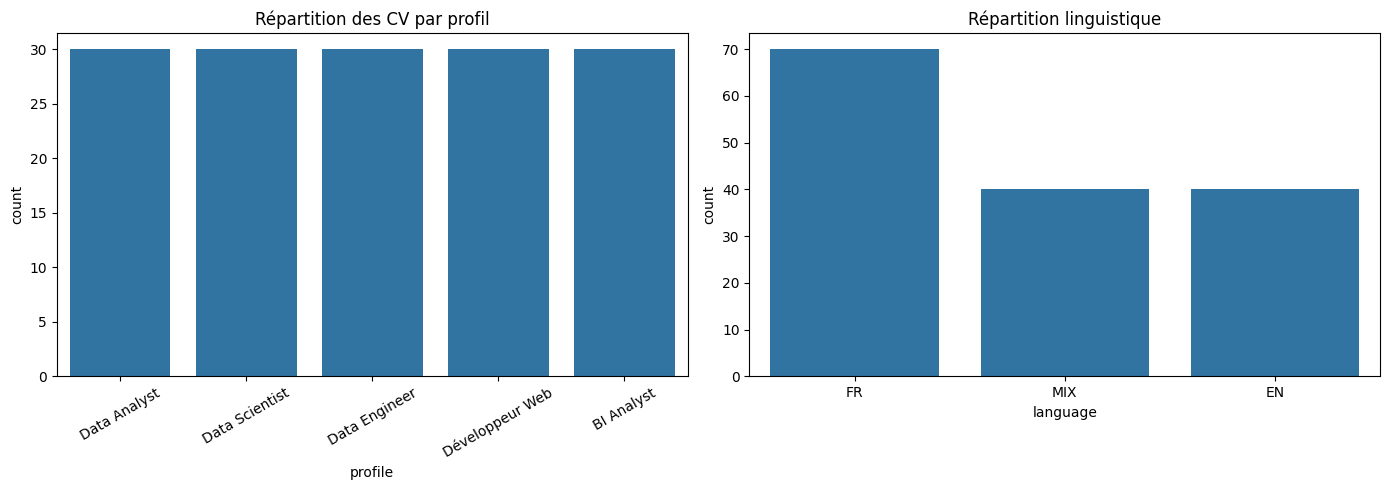


Dataset sauvegardé avec succès.
Fichiers : [WindowsPath('c:/Users/Lenovo/Documents/emsi5/nlp/projet/CV_JOB_MATCHING/data/raw/cvs_synthetic.csv'), WindowsPath('c:/Users/Lenovo/Documents/emsi5/nlp/projet/CV_JOB_MATCHING/data/raw/job_offers_synthetic.csv')]


In [8]:
# Vérification des CV
print("Dimensions du dataset CV :", cvs_df.shape)
print("\nCV par profil :")
display(cvs_df["profile"].value_counts())

print("\nRépartition linguistique :")
display(cvs_df["language"].value_counts())

print("\nValeurs manquantes :")
display(cvs_df.isnull().sum())

print("\nCV dupliqués :", cvs_df["cv_text"].duplicated().sum())

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=cvs_df, x="profile", ax=axes[0])
axes[0].set_title("Répartition des CV par profil")
axes[0].tick_params(axis="x", rotation=30)

sns.countplot(data=cvs_df, x="language", ax=axes[1])
axes[1].set_title("Répartition linguistique")

plt.tight_layout()
plt.show()

# Sauvegarde
cvs_export = cvs_df.copy()
offers_export = offers_df.copy()

cvs_export["skills"] = cvs_export["skills"].apply(
    lambda x: json.dumps(x, ensure_ascii=False)
)

offers_export["required_skills"] = offers_export["required_skills"].apply(
    lambda x: json.dumps(x, ensure_ascii=False)
)

cvs_export.to_csv(
    DATA_RAW / "cvs_synthetic.csv",
    index=False,
    encoding="utf-8-sig"
)

offers_export.to_csv(
    DATA_RAW / "job_offers_synthetic.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDataset sauvegardé avec succès.")
print("Fichiers :", list(DATA_RAW.glob("*.csv")))

In [9]:
# Vérification de la diversité des CV

print("Nombre de textes CV uniques :",
      cvs_df["cv_text"].nunique())

print("\nLongueur moyenne des CV (caractères) :",
      cvs_df["cv_text"].str.len().mean())

print("\nLongueur minimale :",
      cvs_df["cv_text"].str.len().min())

print("\nLongueur maximale :",
      cvs_df["cv_text"].str.len().max())

# Afficher un exemple par langue
for lang in ["FR", "MIX", "EN"]:
    print(f"\n{'='*50}")
    print(f"EXEMPLE CV - {lang}")
    print(f"{'='*50}")

    sample = cvs_df[cvs_df["language"] == lang].iloc[0]
    print(sample["cv_text"])

Nombre de textes CV uniques : 150

Longueur moyenne des CV (caractères) : 557.1933333333334

Longueur minimale : 392

Longueur maximale : 799

EXEMPLE CV - FR
PROFIL PROFESSIONNEL

Candidat(e) au poste de Junior Data Analyst, spécialisé(e) en Data Analyst.
Formation : Master en Analyse de données, obtenue en 2022.

DOMAINES DE COMPÉTENCE
Matplotlib, Statistiques, SQL, Tableau, Python

RÉALISATIONS ET EXPÉRIENCES
Stage chez Atlas Digital (2022-2022), 3 mois : Automatisation de rapports à l'aide de Python et SQL.

ÉTUDES
École d'Ingénierie Numérique

Localisation : Casablanca

EXEMPLE CV - MIX
Lina Alaoui

PROFIL PROFESSIONNEL / CAREER PROFILE
Spécialisé(e) en Data Analyst, avec un intérêt pour les projets Data & IT.
Interested in developing technical solutions and analyzing complex datasets.

EXPERTISE / SKILLS
SQL, Statistiques, Excel, Pandas, Matplotlib

PARCOURS PROFESSIONNEL / PROFESSIONAL EXPERIENCE
Stage chez Innovatech (2022-2022), 4 mois : Nettoyage des données et préparation de

## 2. Annotation NER : pré-annotation automatique et validation

**Schéma d'entités** : `COMPETENCE`, `POSTE`, `DIPLOME`, `ORG`, `DATE`.

**Démarche.** Les 150 CV sont pré-annotés avec un dictionnaire (compétences, postes, diplômes, organisations) et une expression régulière pour les dates. Un échantillon de 30 CV (2 par profil et par langue) est exporté en CSV pour une **validation manuelle** ; les corrections sont ensuite réappliquées.

In [10]:
def build_entity_dictionary(cvs_df, profiles, organizations):
    d = {"COMPETENCE": set(), "POSTE": set(), "DIPLOME": set(), "ORG": set(organizations)}
    for info in profiles.values():
        d["COMPETENCE"].update(info["skills"])
        d["POSTE"].update(info["positions"])
        d["DIPLOME"].update(info["degrees"])
    d["DIPLOME"].update(cvs_df["degree"].unique())   # inclut les diplômes traduits en anglais
    return d

ENTITY_DICTIONARY = build_entity_dictionary(cvs_df, profiles, organizations)

DATE_PATTERN = re.compile(r"(?<!\d)(?:19|20)\d{2}(?:\s*[-–/]\s*(?:19|20)\d{2})?(?!\d)")
SPECIALTY_CONTEXT = re.compile(r"(?:sp[eé]cialis[eé](?:\(e\))?|specialized)\s+(?:en|in)\s*$", re.IGNORECASE)

def automatic_annotation(text, dictionary):
    candidates = []
    for label, expressions in dictionary.items():
        for expr in expressions:
            pattern = r"(?<!\w)" + re.escape(expr) + r"(?!\w)"      # mots entiers uniquement
            flags = re.IGNORECASE if " " in expr else 0               # casse respectée pour les mots simples
            for m in re.finditer(pattern, text, flags):
                candidates.append((m.start(), m.end(), label))
    for m in DATE_PATTERN.finditer(text):
        candidates.append((m.start(), m.end(), "DATE"))

    # chevauchements : on garde d'abord les expressions les plus longues
    candidates.sort(key=lambda x: (-(x[1] - x[0]), x[0]))
    selected = []
    for s, e, l in candidates:
        if not any(s < e2 and s2 < e for s2, e2, _ in selected):
            selected.append((s, e, l))
    selected = sorted(selected)

    # un intitulé de poste utilisé comme « spécialité » n'est pas un POSTE
    cleaned = []
    for s, e, l in selected:
        if l == "POSTE" and SPECIALTY_CONTEXT.search(text[max(0, s - 40):s]):
            continue
        cleaned.append((s, e, l))
    return cleaned

In [11]:
ANN = []
for _, row in cvs_df.iterrows():
    ANN.append({
        "cv_id": int(row["cv_id"]),
        "profile": row["profile"],
        "language": row["language"],
        "name": row["name"],
        "text": row["cv_text"],
        "entities": automatic_annotation(row["cv_text"], ENTITY_DICTIONARY),
    })

ann_df = pd.DataFrame(
    [(a["cv_id"], a["profile"], a["language"], l) for a in ANN for _, _, l in a["entities"]],
    columns=["cv_id", "profile", "language", "label"],
)
print("CV annotés :", len(ANN), "| entités :", len(ann_df))
display(pd.crosstab(ann_df["label"], ann_df["language"], margins=True))
display(pd.crosstab(ann_df["label"], ann_df["profile"], margins=True))

# contrôle : aucune entité vide ou aux bornes sur un espace
bad = [(a["cv_id"], a["text"][s:e]) for a in ANN for s, e, _ in a["entities"]
       if not a["text"][s:e].strip() or a["text"][s:e] != a["text"][s:e].strip()]
print("Entités invalides :", len(bad))

CV annotés : 150 | entités : 1890


language,EN,FR,MIX,All
label,,,,
COMPETENCE,300,515,328,1143
DATE,80,140,80,300
DIPLOME,40,88,40,168
ORG,40,70,40,150
POSTE,40,70,19,129
All,500,883,507,1890


profile,BI Analyst,Data Analyst,Data Engineer,Data Scientist,Développeur Web,All
label,,,,,,
COMPETENCE,229,243,230,215,226,1143
DATE,60,60,60,60,60,300
DIPLOME,32,35,35,31,35,168
ORG,30,30,30,30,30,150
POSTE,24,28,25,26,26,129
All,375,396,380,362,377,1890


Entités invalides : 0


In [12]:
# Visualisation d'un CV annoté par langue
try:
    import spacy
    from spacy import displacy
    _blank = spacy.blank("fr")
    for lang in ["FR", "MIX", "EN"]:
        item = next(a for a in ANN if a["language"] == lang)
        doc = _blank.make_doc(item["text"])
        spans = [doc.char_span(s, e, label=l, alignment_mode="contract") for s, e, l in item["entities"]]
        doc.ents = [sp for sp in spans if sp is not None]
        print(f"\nCV {item['cv_id']} — {item['profile']} — {lang}")
        displacy.render(doc, style="ent", jupyter=True)
except ImportError:
    print("spaCy non installé : visualisation ignorée.")


CV 1 — Data Analyst — FR



CV 15 — Data Analyst — MIX



CV 23 — Data Analyst — EN


In [13]:
# Contrôle d'alignement entre les entités et les tokens spaCy (mode strict)
try:
    import spacy
    _blank = spacy.blank("fr")
    misaligned = []
    for a in ANN:
        doc = _blank.make_doc(a["text"])
        for s, e, l in a["entities"]:
            if doc.char_span(s, e, label=l, alignment_mode="strict") is None:
                misaligned.append({"cv_id": a["cv_id"], "entité": a["text"][s:e], "label": l})
    total = sum(len(a["entities"]) for a in ANN)
    print(f"Entités : {total} | non alignées : {len(misaligned)} ({100*len(misaligned)/total:.2f} %)")
    display(pd.DataFrame(misaligned).head(15))
except ImportError:
    print("spaCy non installé : contrôle ignoré.")

Entités : 1890 | non alignées : 0 (0.00 %)


""


### 2.1 Validation manuelle d'un échantillon dans Label Studio

Un échantillon de **30 CV** (2 par profil et par langue, tirés avec une graine fixée) est exporté vers **Label Studio** (`label_studio_tasks.json`) avec ses entités pré-annotées et la configuration des cinq types d'entités (`label_studio_config.xml`). Chaque CV est relu et corrigé à la main, puis l'export JSON (`label_studio_export.json`) est réimporté dans le notebook : les annotations corrigées remplacent les annotations automatiques de ces 30 CV.

La cellule d'import mesure la **qualité de la pré-annotation** en la comparant à la version corrigée (précision, rappel, F1, nombre d'entités conservées, supprimées et ajoutées). Les 120 autres CV conservent leur annotation automatique ; les résultats du NER sont donc mesurés en partie sur des annotations non relues, ce qui est discuté dans les limites.

In [14]:
REVIEW_PER_STRATUM = 2
rng_rev = random.Random(SEED)
review_ids = []
for (_p, _l), grp in pd.DataFrame(ANN)[["cv_id", "profile", "language"]].groupby(["profile", "language"]):
    ids = sorted(grp["cv_id"].tolist())
    review_ids += rng_rev.sample(ids, min(REVIEW_PER_STRATUM, len(ids)))
review_ids = sorted(review_ids)

by_id = {a["cv_id"]: a for a in ANN}
rows = []
for cid in review_ids:
    a = by_id[cid]
    for s, e, l in a["entities"]:
        ctx = a["text"][max(0, s - 50):e + 50].replace("\n", " ")
        rows.append({"cv_id": cid, "profile": a["profile"], "language": a["language"],
                     "entity": a["text"][s:e], "label": l, "start": s, "end": e,
                     "context": ctx, "validation": "", "corrected_label": ""})
review_df = pd.DataFrame(rows)
review_path = DATA_PROCESSED / "annotations_to_review.csv"
review_df.to_csv(review_path, index=False, encoding="utf-8-sig")
print(f"{len(review_ids)} CV à valider, {len(review_df)} entités -> {review_path}")
display(review_df.head(10))

30 CV à valider, 383 entités -> c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\data\processed\annotations_to_review.csv


,cv_id,profile,language,entity,label,start,end,context,validation,corrected_label
0,2,Data Analyst,FR,Junior Data Analyst,POSTE,0,19,"Junior Data Analyst PROFIL Hiba Naciri, diplômé(e) en Master en Data",,
1,2,Data Analyst,FR,Master en Data Science,DIPLOME,55,77,"r Data Analyst PROFIL Hiba Naciri, diplômé(e) en Master en Data Science, sp...",,
2,2,Data Analyst,FR,Tableau,COMPETENCE,231,238,"analyse des performances. COMPÉTENCES TECHNIQUES Tableau, NumPy, Pandas, Po...",,
3,2,Data Analyst,FR,NumPy,COMPETENCE,240,245,"es performances. COMPÉTENCES TECHNIQUES Tableau, NumPy, Pandas, Power BI, S...",,
4,2,Data Analyst,FR,Pandas,COMPETENCE,247,253,"ormances. COMPÉTENCES TECHNIQUES Tableau, NumPy, Pandas, Power BI, SQL, Dat...",,
5,2,Data Analyst,FR,Power BI,COMPETENCE,255,263,". COMPÉTENCES TECHNIQUES Tableau, NumPy, Pandas, Power BI, SQL, Data Visual...",,
6,2,Data Analyst,FR,SQL,COMPETENCE,265,268,"NCES TECHNIQUES Tableau, NumPy, Pandas, Power BI, SQL, Data Visualization E...",,
7,2,Data Analyst,FR,Data Visualization,COMPETENCE,270,288,"TECHNIQUES Tableau, NumPy, Pandas, Power BI, SQL, Data Visualization EXPÉRI...",,
8,2,Data Analyst,FR,NovaTech,ORG,328,336,"ualization EXPÉRIENCE PROFESSIONNELLE Stage chez NovaTech (2022-2022), 3 mo...",,
9,2,Data Analyst,FR,2022-2022,DATE,338,347,"EXPÉRIENCE PROFESSIONNELLE Stage chez NovaTech (2022-2022), 3 mois : Conce...",,


In [15]:
# ---- Export des 30 CV pré-annotés vers Label Studio
LS_CONFIG = """<View>
  <Labels name="label" toName="text">
    <Label value="COMPETENCE" background="#2a9d8f"/>
    <Label value="DATE" background="#e9c46a"/>
    <Label value="DIPLOME" background="#e76f51"/>
    <Label value="ORG" background="#457b9d"/>
    <Label value="POSTE" background="#9b5de5"/>
  </Labels>
  <Text name="text" value="$text" valueType="text"/>
</View>"""

ls_tasks = []
for cid in review_ids:
    a = by_id[cid]
    ls_tasks.append({
        "data": {"text": a["text"], "cv_id": cid},
        "predictions": [{
            "model_version": "pre-annotation-dictionnaire",
            "result": [{"from_name": "label", "to_name": "text", "type": "labels",
                        "value": {"start": s, "end": e, "text": a["text"][s:e], "labels": [l]}}
                       for s, e, l in a["entities"]],
        }],
    })
with open(DATA_PROCESSED / "label_studio_tasks.json", "w", encoding="utf-8") as f:
    json.dump(ls_tasks, f, ensure_ascii=False, indent=1)
with open(DATA_PROCESSED / "label_studio_config.xml", "w", encoding="utf-8") as f:
    f.write(LS_CONFIG)
print(f"{len(ls_tasks)} CV exportés -> label_studio_tasks.json (+ label_studio_config.xml)")

30 CV exportés -> label_studio_tasks.json (+ label_studio_config.xml)


In [16]:
# ---- Import des corrections faites dans Label Studio
LS_EXPORT = DATA_PROCESSED / "label_studio_export.json"

def ls_entities(task):
    anns = [a for a in task.get("annotations", []) if not a.get("was_cancelled")]
    if not anns:
        return None
    ents = []
    for r in anns[-1]["result"]:
        if r.get("type") == "labels":
            v = r["value"]
            if v["labels"][0] in ENTITY_TYPES:
                ents.append((int(v["start"]), int(v["end"]), v["labels"][0]))
    return sorted(set(ents))

if LS_EXPORT.exists():
    tasks = json.load(open(LS_EXPORT, encoding="utf-8"))
    tp = fp = fn = 0
    n_done = 0
    for t in tasks:
        human = ls_entities(t)
        if human is None:
            continue                       # tâche non soumise : annotations automatiques conservées
        a = by_id[int(t["data"]["cv_id"])]
        auto = set(a["entities"])
        tp += len(auto & set(human)); fp += len(auto - set(human)); fn += len(set(human) - auto)
        a["entities"] = human
        a["reviewed"] = True
        n_done += 1
    P, R = tp / (tp + fp), tp / (tp + fn)
    print(f"{n_done}/{len(tasks)} CV corrigés dans Label Studio")
    print(f"Pré-annotation automatique vs annotation humaine : précision {P:.3f} | rappel {R:.3f} | F1 {2*P*R/(P+R):.3f}")
    print(f"({tp} entités conservées, {fp} supprimées ou modifiées, {fn} ajoutées ou modifiées)")
else:
    print("Pas d'export Label Studio trouvé :", LS_EXPORT)
    print("Annotations automatiques conservées (à signaler dans l'article).")

30/30 CV corrigés dans Label Studio
Pré-annotation automatique vs annotation humaine : précision 1.000 | rappel 0.958 | F1 0.978
(383 entités conservées, 0 supprimées ou modifiées, 17 ajoutées ou modifiées)


## 3. Découpage train / dev / test

Découpage **par CV** (jamais par phrase), stratifié par profil et par langue, avec graine fixée :
- **train** (70 %) : entraînement des modèles ;
- **dev** (15 %) : choix du modèle, du seuil de normalisation, des hyperparamètres ;
- **test** (15 %) : évaluation finale, jamais utilisée pour choisir quoi que ce soit.

In [17]:
from sklearn.model_selection import train_test_split

strata = [f"{a['profile']}|{a['language']}" for a in ANN]
idx = np.arange(len(ANN))
tr_idx, test_idx = train_test_split(idx, test_size=0.15, random_state=SEED, stratify=strata)
tr_idx, dev_idx = train_test_split(tr_idx, test_size=0.15 / 0.85, random_state=SEED,
                                   stratify=[strata[i] for i in tr_idx])

TRAIN = [ANN[i] for i in tr_idx]
DEV = [ANN[i] for i in dev_idx]
TEST = [ANN[i] for i in test_idx]

split_df = pd.DataFrame({"split": ["train"] * len(TRAIN) + ["dev"] * len(DEV) + ["test"] * len(TEST),
                         "cv_id": [a["cv_id"] for a in TRAIN + DEV + TEST],
                         "language": [a["language"] for a in TRAIN + DEV + TEST],
                         "profile": [a["profile"] for a in TRAIN + DEV + TEST]})
split_df.to_csv(DATA_PROCESSED / "split.csv", index=False)

print({k: len(v) for k, v in [("train", TRAIN), ("dev", DEV), ("test", TEST)]})
display(pd.crosstab(split_df["split"], split_df["language"]))
display(pd.crosstab(split_df["split"], split_df["profile"]))
assert not (set(a["cv_id"] for a in TRAIN) & set(a["cv_id"] for a in TEST)), "fuite train/test"

{'train': 104, 'dev': 23, 'test': 23}


language,EN,FR,MIX
split,,,
dev,5,10,8
test,7,10,6
train,28,50,26


profile,BI Analyst,Data Analyst,Data Engineer,Data Scientist,Développeur Web
split,,,,,
dev,5,4,5,4,5
test,4,4,5,6,4
train,21,22,20,20,21


## 4. Métrique d'évaluation : F1 par entité complète

Une entité prédite est correcte si **son début, sa fin et son type** correspondent exactement à ceux de l'entité de référence. Tous les modèles (spaCy, CamemBERT, variantes) sont comparés avec **la même fonction**, sur les mêmes CV.

In [18]:
def gold_sets(recs):
    return [set(map(tuple, r["entities"])) for r in recs]

def entity_prf(gold, pred, labels=ENTITY_TYPES):
    tp, fp, fn = Counter(), Counter(), Counter()
    for g, p in zip(gold, pred):
        g, p = set(map(tuple, g)), set(map(tuple, p))
        for ent in p:
            (tp if ent in g else fp)[ent[2]] += 1
        for ent in g:
            if ent not in p:
                fn[ent[2]] += 1

    def prf(t, f_p, f_n):
        P = t / (t + f_p) if t + f_p else 0.0
        R = t / (t + f_n) if t + f_n else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        return P, R, F

    rows = []
    for l in labels:
        P, R, F = prf(tp[l], fp[l], fn[l])
        rows.append({"type": l, "precision": P, "recall": R, "f1": F, "support": tp[l] + fn[l]})
    macro = {"type": "macro", "precision": np.mean([r["precision"] for r in rows]),
             "recall": np.mean([r["recall"] for r in rows]), "f1": np.mean([r["f1"] for r in rows]),
             "support": sum(r["support"] for r in rows)}
    P, R, F = prf(sum(tp.values()), sum(fp.values()), sum(fn.values()))
    rows.append({"type": "micro", "precision": P, "recall": R, "f1": F, "support": sum(tp.values()) + sum(fn.values())})
    rows.append(macro)
    return pd.DataFrame(rows).set_index("type")

def evaluate_ner(pred_fn, recs):
    preds = pred_fn([r["text"] for r in recs])
    return entity_prf(gold_sets(recs), preds), preds

def f1_by_group(preds, recs, key):
    gs, out = gold_sets(recs), {}
    for g in sorted({r[key] for r in recs}):
        ii = [i for i, r in enumerate(recs) if r[key] == g]
        out[g] = entity_prf([gs[i] for i in ii], [preds[i] for i in ii]).loc["micro", "f1"]
    return out

# test unitaire de la métrique
_g = [{(0, 5, "ORG"), (10, 15, "DATE")}]
_p = [{(0, 5, "ORG"), (10, 16, "DATE")}]          # frontière erronée -> faux positif + faux négatif
_r = entity_prf(_g, _p)
assert abs(_r.loc["ORG", "f1"] - 1.0) < 1e-9 and _r.loc["DATE", "f1"] == 0.0
print("Métrique vérifiée.")

Métrique vérifiée.


In [19]:
# ---- CELLULE DE REPRISE : recharge les modèles déjà entraînés depuis le disque (aucun entraînement)
import spacy, torch
from transformers import AutoTokenizer, AutoModelForTokenClassification

# --- spaCy (base de référence)
nlp_spacy = spacy.load(str(MODELS_DIR / "ner_spacy_baseline"))

def predict_spacy(nlp, texts):
    return [set((e.start_char, e.end_char, e.label_) for e in nlp(t).ents if e.label_ in ENTITY_TYPES) for t in texts]

NER_FNS["spacy"] = lambda texts: predict_spacy(nlp_spacy, texts)

# --- CamemBERT (modèle principal) avec correction de décodage (ponctuation aux bornes)
tok_cam = AutoTokenizer.from_pretrained(str(MODELS_DIR / "ner_camembert"))
model_cam = AutoModelForTokenClassification.from_pretrained(str(MODELS_DIR / "ner_camembert")).to(DEVICE).eval()
id2label = {int(k): v for k, v in model_cam.config.id2label.items()}
STRIP_LEFT = "([{«\"'“‘"
STRIP_RIGHT = ")]}»\"'”’,;:."

def predict_entities_hf(model, tok, text, max_length=512):
    enc = tok(text, return_offsets_mapping=True, truncation=True, max_length=max_length, return_tensors="pt")
    offsets = enc.pop("offset_mapping")[0].tolist()
    dev = next(model.parameters()).device
    with torch.no_grad():
        pred = model(**{k: v.to(dev) for k, v in enc.items()}).logits.argmax(-1)[0].cpu().tolist()
    ents, cur = [], None
    for p, (a, b) in zip(pred, offsets):
        if a == b:
            continue
        tag = id2label[p]
        if tag == "O":
            if cur: ents.append(cur); cur = None
            continue
        prefix, lab = tag.split("-", 1)
        if prefix == "B" or cur is None or cur[2] != lab:
            if cur: ents.append(cur)
            cur = [a, b, lab]
        else:
            cur[1] = b
    if cur:
        ents.append(cur)
    out = set()
    for s, e, l in ents:
        while s < e and (text[s].isspace() or text[s] in STRIP_LEFT): s += 1
        while e > s and (text[e - 1].isspace() or text[e - 1] in STRIP_RIGHT): e -= 1
        if s < e:
            out.add((s, e, l))
    return out

NER_FNS["camembert"] = lambda texts: [predict_entities_hf(model_cam, tok_cam, t) for t in texts]
EXTRACTOR_NAME = "spacy"          # extracteur retenu lors de l'exécution complète

# --- Comparaison NER recalculée (CamemBERT après correction de décodage)
rows = []
for label, name in [("spaCy", "spacy"), ("CamemBERT", "camembert")]:
    for split_name, recs in [("dev", DEV), ("test", TEST)]:
        res, _ = evaluate_ner(NER_FNS[name], recs)
        rows.append({"modèle": f"{label} ({split_name})", **{t: res.loc[t, "f1"] for t in ENTITY_TYPES},
                     "micro-F1": res.loc["micro", "f1"], "macro-F1": res.loc["macro", "f1"]})
comparison_ner = pd.DataFrame(rows).set_index("modèle")
RESULTS["ner_comparison"] = comparison_ner
display(comparison_ner.round(4))

# --- Résultats de la partie 13 (audit d'équité) déjà calculés lors de l'exécution complète
mitig = pd.read_csv(REPORTS_DIR / "mitigation_equite.csv", index_col=0)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,COMPETENCE,DATE,DIPLOME,ORG,POSTE,micro-F1,macro-F1
modèle,,,,,,,
spaCy (dev),0.9880,1.0,1.0000,1.0,0.9730,0.9910,0.9922
spaCy (test),1.0000,1.0,1.0000,1.0,1.0000,1.0000,1.0000
CamemBERT (dev),0.9763,1.0,0.5161,1.0,0.6286,0.9110,0.8242
CamemBERT (test),0.9831,1.0,0.3333,1.0,0.4286,0.8713,0.7490


## 5. Base de référence : spaCy

Pipeline `spacy.blank("fr")` avec un composant NER entraîné **uniquement sur le jeu `train`**. Le jeu `dev` sert au choix du modèle, le jeu `test` à l'évaluation finale.

> Dans la première version du notebook, le F1 de spaCy valait 1,00 sur 6 CV de validation : un score parfait sur un si petit échantillon n'est pas interprétable. Ici l'évaluation porte sur 23 CV de test, et le volet robustesse (partie 14) permet de départager les modèles de façon plus discriminante.

In [18]:
import spacy
from spacy.training import Example
from spacy.util import minibatch

def make_examples(nlp, recs):
    examples, skipped = [], 0
    for r in recs:
        doc = nlp.make_doc(r["text"])
        ents = []
        for s, e, l in r["entities"]:
            if doc.char_span(s, e, label=l, alignment_mode="strict") is not None:
                ents.append((s, e, l))
            else:
                skipped += 1
        examples.append(Example.from_dict(doc, {"entities": ents}))
    return examples, skipped

def train_spacy(train_recs, epochs=SPACY_EPOCHS, seed=SEED, verbose=True):
    spacy.util.fix_random_seed(seed)
    rng = random.Random(seed)
    nlp = spacy.blank("fr")
    ner = nlp.add_pipe("ner")
    for l in ENTITY_TYPES:
        ner.add_label(l)
    examples, skipped = make_examples(nlp, train_recs)
    optimizer = nlp.initialize(lambda: examples)
    for ep in range(epochs):
        rng.shuffle(examples)
        losses = {}
        for batch in minibatch(examples, size=4):
            nlp.update(batch, drop=0.2, sgd=optimizer, losses=losses)
        if verbose and (ep + 1) % 10 == 0:
            print(f"  époque {ep + 1}/{epochs} | perte NER : {losses.get('ner', 0):.4f}")
    if verbose:
        print(f"  entités ignorées (non alignées) : {skipped}")
    return nlp

def predict_spacy(nlp, texts):
    return [set((e.start_char, e.end_char, e.label_) for e in nlp(t).ents if e.label_ in ENTITY_TYPES)
            for t in texts]

set_seed(SEED)
nlp_spacy = train_spacy(TRAIN)
nlp_spacy.to_disk(MODELS_DIR / "ner_spacy_baseline")
NER_FNS["spacy"] = lambda texts: predict_spacy(nlp_spacy, texts)
print("Modèle spaCy sauvegardé dans", MODELS_DIR / "ner_spacy_baseline")

  époque 10/40 | perte NER : 23.5879
  époque 20/40 | perte NER : 22.3859
  époque 30/40 | perte NER : 23.6347
  époque 40/40 | perte NER : 23.6985
  entités ignorées (non alignées) : 2
Modèle spaCy sauvegardé dans c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\models\ner_spacy_baseline


In [19]:
res_spacy_dev, _ = evaluate_ner(NER_FNS["spacy"], DEV)
res_spacy_test, pred_spacy_test = evaluate_ner(NER_FNS["spacy"], TEST)
print("spaCy — DEV");  display(res_spacy_dev.round(4))
print("spaCy — TEST"); display(res_spacy_test.round(4))

spaCy — DEV


,precision,recall,f1,support
type,,,,
COMPETENCE,1.0000,0.9763,0.9880,169
DATE,1.0000,1.0000,1.0000,46
DIPLOME,1.0000,1.0000,1.0000,24
ORG,1.0000,1.0000,1.0000,23
POSTE,0.9474,1.0000,0.9730,18
micro,0.9964,0.9857,0.9910,280
macro,0.9895,0.9953,0.9922,280


spaCy — TEST


,precision,recall,f1,support
type,,,,
COMPETENCE,1.0,1.0,1.0,174
DATE,1.0,1.0,1.0,46
DIPLOME,1.0,1.0,1.0,26
ORG,1.0,1.0,1.0,23
POSTE,1.0,1.0,1.0,21
micro,1.0,1.0,1.0,290
macro,1.0,1.0,1.0,290


## 6. Modèle avancé : CamemBERT (classification de tokens)

`camembert-base` est fine-tuné pour l'étiquetage BIO au niveau des sous-mots ; les prédictions sont ensuite reconstruites en **entités sur les caractères** pour être évaluées avec la même métrique que spaCy.

**Paramètres d'entraînement.** 15 époques, taux d'apprentissage 5e-5, lots de 8, décroissance de poids 0,01, graine 42. Le modèle est entraîné sur le jeu `train` (104 CV) ; `dev` sert au suivi de la perte.

**Évaluation.** L'évaluation se fait au niveau de l'entité complète, avec la fonction de la partie 4, pour tous les modèles. Une même fonction d'entraînement est réutilisée pour les ablations (perte pondérée, taille du jeu d'entraînement, bruit).

**Décodage.** Une étape de décodage retire la ponctuation parasite aux bornes des entités prédites (par exemple « (2022-2023 » devient « 2022-2023 »). Elle est appliquée dans la cellule de reprise ; les sorties des parties 5 à 8 et 14 datent d'avant ce correctif, et le tableau de référence est celui de la cellule de reprise.

In [20]:
from transformers import (AutoTokenizer, AutoModelForTokenClassification, TrainingArguments,
                          Trainer, DataCollatorForTokenClassification)

label_list = ["O"] + [f"{p}-{l}" for l in ENTITY_TYPES for p in ("B", "I")]
label2id = {l: i for i, l in enumerate(label_list)}
id2label = {i: l for l, i in label2id.items()}

def encode_records(recs, tok, max_length=512):
    items, truncated = [], 0
    for r in recs:
        enc = tok(r["text"], truncation=True, max_length=max_length, return_offsets_mapping=True)
        offsets = enc["offset_mapping"]
        truncated += int(len(enc["input_ids"]) >= max_length)
        tags = ["O"] * len(offsets)
        for s, e, l in r["entities"]:
            hit = [i for i, (a, b) in enumerate(offsets) if a < b and a < e and b > s]
            for k, i in enumerate(hit):
                tags[i] = ("B-" if k == 0 else "I-") + l
        labels = [-100 if a == b else label2id[t] for (a, b), t in zip(offsets, tags)]
        items.append({"input_ids": list(enc["input_ids"]),
                      "attention_mask": list(enc["attention_mask"]),
                      "labels": labels})
    if truncated:
        print(f"Attention : {truncated} CV tronqués à {max_length} sous-mots")
    return items

class CVDataset(torch.utils.data.Dataset):
    def __init__(self, items):
        self.items = items
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return {k: torch.tensor(v) for k, v in self.items[i].items()}

def compute_class_weights(items, cap=8.0):
    counts = Counter(l for it in items for l in it["labels"] if l != -100)
    total = sum(counts.values())
    w = [min(math.sqrt(total / counts.get(i, 1)), cap) for i in range(len(label_list))]
    return torch.tensor(w, dtype=torch.float)

class WeightedTrainer(Trainer):
    class_weights = None
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=self.class_weights.to(outputs.logits.device), ignore_index=-100)
        loss = loss_fn(outputs.logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def predict_entities_hf(model, tok, text, max_length=512):
    enc = tok(text, return_offsets_mapping=True, truncation=True, max_length=max_length, return_tensors="pt")
    offsets = enc.pop("offset_mapping")[0].tolist()
    dev = next(model.parameters()).device
    with torch.no_grad():
        pred = model(**{k: v.to(dev) for k, v in enc.items()}).logits.argmax(-1)[0].cpu().tolist()
    ents, cur = [], None
    for p, (a, b) in zip(pred, offsets):
        if a == b:
            continue
        tag = id2label[p]
        if tag == "O":
            if cur: ents.append(cur); cur = None
            continue
        prefix, lab = tag.split("-", 1)
        if prefix == "B" or cur is None or cur[2] != lab:
            if cur: ents.append(cur)
            cur = [a, b, lab]
        else:
            cur[1] = b
    if cur:
        ents.append(cur)
    out = set()
    for s, e, l in ents:
        while s < e and text[s].isspace(): s += 1
        while e > s and text[e - 1].isspace(): e -= 1
        if s < e:
            out.add((s, e, l))
    return out

def make_hf_predictor(model, tok):
    model.eval()
    return lambda texts: [predict_entities_hf(model, tok, t) for t in texts]

def train_hf(train_recs, dev_recs, model_name=HF_MODEL, tag="camembert", epochs=HF_EPOCHS,
             lr=HF_LR, bs=HF_BS, weighted=False, seed=SEED):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    model = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(label_list), id2label=id2label, label2id=label2id)
    train_items, dev_items = encode_records(train_recs, tok), encode_records(dev_recs, tok)
    args = TrainingArguments(
        output_dir=str(MODELS_DIR / f"ckpt_{tag}"), num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=bs, per_device_eval_batch_size=8, weight_decay=0.01,
        eval_strategy="epoch", save_strategy="no", logging_strategy="epoch",
        report_to="none", seed=seed, dataloader_pin_memory=False, fp16=(DEVICE == "cuda"))
    cls = WeightedTrainer if weighted else Trainer
    trainer = cls(model=model, args=args, train_dataset=CVDataset(train_items),
                  eval_dataset=CVDataset(dev_items),
                  data_collator=DataCollatorForTokenClassification(tok))
    if weighted:
        trainer.class_weights = compute_class_weights(train_items)
    trainer.train()
    model.to(DEVICE)
    return model, tok, trainer.state.log_history

def plot_history(log, title):
    tr = [(l["epoch"], l["loss"]) for l in log if "loss" in l]
    ev = [(l["epoch"], l["eval_loss"]) for l in log if "eval_loss" in l]
    plt.figure(figsize=(6, 3.5))
    if tr: plt.plot(*zip(*tr), marker="o", label="train")
    if ev: plt.plot(*zip(*ev), marker="s", label="dev")
    plt.xlabel("époque"); plt.ylabel("perte"); plt.title(title); plt.legend(); plt.grid(alpha=.3)
    plt.tight_layout(); plt.show()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,1.822308,1.323927
2,1.289072,1.103193
3,1.105756,0.971582
4,1.002824,0.889628
5,0.922766,0.821198
6,0.856905,0.759740
7,0.797601,0.700367
8,0.734082,0.630019
9,0.665354,0.583457
10,0.621672,0.550381


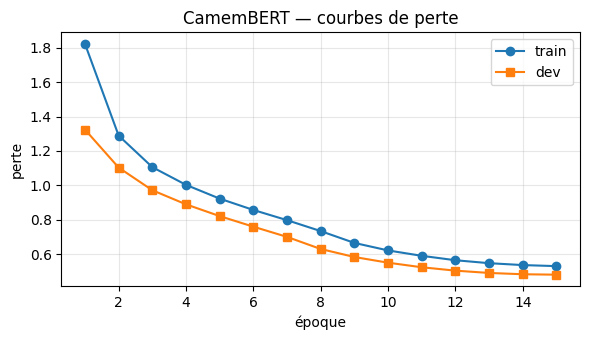

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('c:\\Users\\Lenovo\\Documents\\emsi5\\nlp\\projet\\CV_JOB_MATCHING\\models\\ner_camembert\\tokenizer_config.json',
 'c:\\Users\\Lenovo\\Documents\\emsi5\\nlp\\projet\\CV_JOB_MATCHING\\models\\ner_camembert\\tokenizer.json')

In [21]:
# Entraînement principal : CamemBERT (perte standard)
model_cam, tok_cam, log_cam = train_hf(TRAIN, DEV, tag="camembert")
plot_history(log_cam, "CamemBERT — courbes de perte")
NER_FNS["camembert"] = make_hf_predictor(model_cam, tok_cam)
model_cam.save_pretrained(MODELS_DIR / "ner_camembert"); tok_cam.save_pretrained(MODELS_DIR / "ner_camembert")

In [22]:
res_cam_dev, _ = evaluate_ner(NER_FNS["camembert"], DEV)
res_cam_test, pred_cam_test = evaluate_ner(NER_FNS["camembert"], TEST)
print("CamemBERT — DEV");  display(res_cam_dev.round(4))
print("CamemBERT — TEST"); display(res_cam_test.round(4))

CamemBERT — DEV


,precision,recall,f1,support
type,,,,
COMPETENCE,0.9763,0.9763,0.9763,169
DATE,0.3913,0.3913,0.3913,46
DIPLOME,0.4211,0.6667,0.5161,24
ORG,1.0000,1.0000,1.0000,23
POSTE,0.6471,0.6111,0.6286,18
micro,0.7952,0.8321,0.8133,280
macro,0.6871,0.7291,0.7025,280


CamemBERT — TEST


,precision,recall,f1,support
type,,,,
COMPETENCE,0.9667,1.0000,0.9831,174
DATE,0.2826,0.2826,0.2826,46
DIPLOME,0.2609,0.4615,0.3333,26
ORG,1.0000,1.0000,1.0000,23
POSTE,0.4286,0.4286,0.4286,21
micro,0.7310,0.7966,0.7624,290
macro,0.5877,0.6345,0.6055,290


## 7. Comparaison, ablations et volet bilingue

### 7.1 Comparaison des modèles (mêmes données, même métrique)

,COMPETENCE,DATE,DIPLOME,ORG,POSTE,micro-F1,macro-F1
modèle,,,,,,,
spaCy (dev),0.9880,1.0000,1.0000,1.0,0.9730,0.9910,0.9922
CamemBERT (dev),0.9763,0.3913,0.5161,1.0,0.6286,0.8133,0.7025
spaCy (test),1.0000,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
CamemBERT (test),0.9831,0.2826,0.3333,1.0,0.4286,0.7624,0.6055


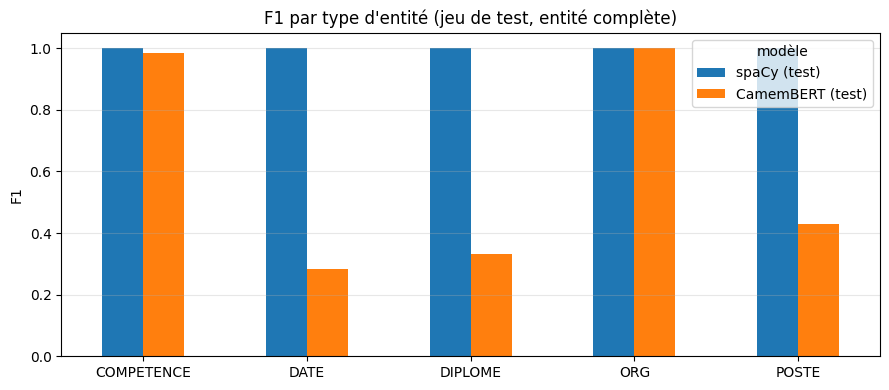

Scores DEV : {'spacy': np.float64(0.991), 'camembert': np.float64(0.8133)}
Extracteur retenu pour la suite : spacy


In [23]:
def summarize(name, res):
    return {"modèle": name, **{t: res.loc[t, "f1"] for t in ENTITY_TYPES},
            "micro-F1": res.loc["micro", "f1"], "macro-F1": res.loc["macro", "f1"]}

comp_rows = [summarize("spaCy (dev)", res_spacy_dev), summarize("CamemBERT (dev)", res_cam_dev),
             summarize("spaCy (test)", res_spacy_test), summarize("CamemBERT (test)", res_cam_test)]
comparison_ner = pd.DataFrame(comp_rows).set_index("modèle")
RESULTS["ner_comparison"] = comparison_ner
display(comparison_ner.round(4))

comparison_ner.loc[["spaCy (test)", "CamemBERT (test)"], ENTITY_TYPES].T.plot(kind="bar", figsize=(9, 4), ylim=(0, 1.05), rot=0)
plt.title("F1 par type d'entité (jeu de test, entité complète)"); plt.ylabel("F1"); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "ner_f1_par_type.png", dpi=150); plt.show()

# Choix du modèle d'extraction pour la suite : meilleur micro-F1 sur DEV (jamais sur TEST)
dev_scores = {"spacy": res_spacy_dev.loc["micro", "f1"], "camembert": res_cam_dev.loc["micro", "f1"]}
EXTRACTOR_NAME = max(dev_scores, key=dev_scores.get)
print("Scores DEV :", {k: round(v, 4) for k, v in dev_scores.items()})
print("Extracteur retenu pour la suite :", EXTRACTOR_NAME)

### 7.2 Ablation : perte pondérée (modèle plus attentif aux classes rares)

In [24]:
if RUN_WEIGHTED_LOSS:
    model_w, tok_w, log_w = train_hf(TRAIN, DEV, tag="camembert_weighted", weighted=True)
    NER_FNS["camembert_weighted"] = make_hf_predictor(model_w, tok_w)
    res_w_test, _ = evaluate_ner(NER_FNS["camembert_weighted"], TEST)
    abl_loss = pd.DataFrame([summarize("CamemBERT perte standard", res_cam_test),
                             summarize("CamemBERT perte pondérée", res_w_test)]).set_index("modèle")
    RESULTS["ablation_perte_ponderee"] = abl_loss
    display(abl_loss.round(4))
else:
    print("Ablation désactivée (RUN_WEIGHTED_LOSS = False)")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,2.056006,1.664176
2,1.549993,1.283296
3,1.237404,1.022292
4,1.023480,0.859298
5,0.893958,0.759238
6,0.803755,0.693079
7,0.739883,0.643691
8,0.711550,0.613368
9,0.663962,0.586434
10,0.638306,0.567122


,COMPETENCE,DATE,DIPLOME,ORG,POSTE,micro-F1,macro-F1
modèle,,,,,,,
CamemBERT perte standard,0.9831,0.2826,0.3333,1.0,0.4286,0.7624,0.6055
CamemBERT perte pondérée,0.9858,0.2826,0.7536,1.0,1.0000,0.8538,0.8044


### 7.3 Ablation : taille du jeu d'entraînement (courbe d'apprentissage)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,2.263903,1.896176
2,1.786240,1.529348
3,1.547680,1.366050
4,1.403954,1.278032
5,1.356419,1.213284
6,1.306275,1.156131
7,1.247467,1.102495
8,1.162480,1.066525
9,1.139649,1.040727
10,1.126206,1.020540


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,2.090841,1.599638
2,1.510922,1.313900
3,1.340869,1.203872
4,1.251341,1.110112
5,1.155616,1.029216
6,1.085411,0.979436
7,1.038664,0.944220
8,1.006134,0.914169
9,0.985822,0.890060
10,0.953351,0.869796


modèle,CamemBERT,spaCy
n_cv,,
26,0.6667,0.9813
52,0.6667,1.0000
104,0.7624,1.0000


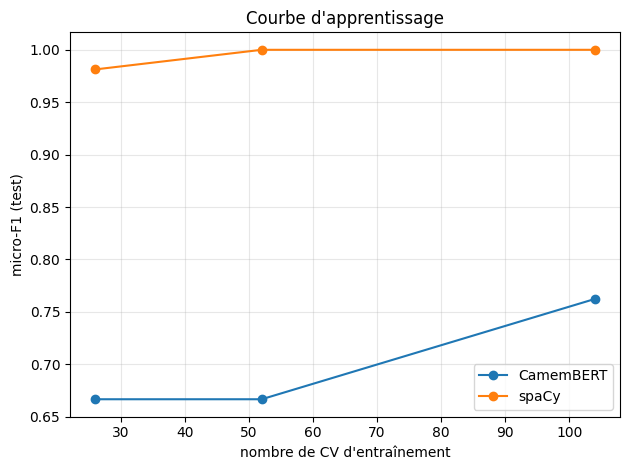

In [25]:
if RUN_LEARNING_CURVE:
    rng_lc = random.Random(SEED)
    shuffled = TRAIN[:]; rng_lc.shuffle(shuffled)
    rows = []
    for frac in (0.25, 0.5, 1.0):
        sub = shuffled[: max(4, int(len(shuffled) * frac))]
        # spaCy
        nlp_sub = train_spacy(sub, verbose=False)
        r_sp, _ = evaluate_ner(lambda t: predict_spacy(nlp_sub, t), TEST)
        rows.append({"fraction": frac, "n_cv": len(sub), "modèle": "spaCy", "micro-F1": r_sp.loc["micro", "f1"]})
        # CamemBERT (la fraction 1.0 réutilise le modèle principal)
        if frac == 1.0:
            f = res_cam_test.loc["micro", "f1"]
        else:
            m_sub, t_sub, _ = train_hf(sub, DEV, tag=f"camembert_{int(frac*100)}")
            f, _p = evaluate_ner(make_hf_predictor(m_sub, t_sub), TEST); f = f.loc["micro", "f1"]
            del m_sub
        rows.append({"fraction": frac, "n_cv": len(sub), "modèle": "CamemBERT", "micro-F1": f})
    lc = pd.DataFrame(rows)
    RESULTS["ablation_taille_train"] = lc
    display(lc.pivot(index="n_cv", columns="modèle", values="micro-F1").round(4))
    for m, g in lc.groupby("modèle"):
        plt.plot(g["n_cv"], g["micro-F1"], marker="o", label=m)
    plt.xlabel("nombre de CV d'entraînement"); plt.ylabel("micro-F1 (test)"); plt.legend(); plt.grid(alpha=.3)
    plt.title("Courbe d'apprentissage"); plt.tight_layout(); plt.show()
else:
    print("Ablation désactivée (RUN_LEARNING_CURVE = False)")

### 7.4 Volet bilingue (apport 2) : performance par langue de CV

Les CV sont en français (`FR`), mixtes (`MIX`) ou en anglais (`EN`). Pour avoir assez d'exemples par langue, l'évaluation porte sur **dev + test** (aucun réglage fin n'a été fait sur ces CV, hormis le choix de l'extracteur).

In [20]:
EVAL_BI = DEV + TEST
rows = []
for name, fn in NER_FNS.items():
    preds = fn([r["text"] for r in EVAL_BI])
    by_lang = f1_by_group(preds, EVAL_BI, "language")
    rows.append({"modèle": name, **{f"F1 {k}": v for k, v in by_lang.items()},
                 "micro-F1 global": entity_prf(gold_sets(EVAL_BI), preds).loc["micro", "f1"]})
by_language = pd.DataFrame(rows).set_index("modèle")
RESULTS["ner_par_langue"] = by_language
display(by_language.round(4))
print("Effectifs :", Counter(r["language"] for r in EVAL_BI))

,F1 EN,F1 FR,F1 MIX,micro-F1 global
modèle,,,,
spacy,1.000,0.9959,0.9915,0.9956
camembert,0.859,0.8789,0.9337,0.8906


Effectifs : Counter({'FR': 20, 'MIX': 14, 'EN': 12})


In [27]:
# Option : modèle multilingue XLM-R, plus adapté aux CV anglais ou mixtes
if RUN_XLMR:
    model_x, tok_x, _ = train_hf(TRAIN, DEV, model_name="xlm-roberta-base", tag="xlmr")
    NER_FNS["xlmr"] = make_hf_predictor(model_x, tok_x)
    px = NER_FNS["xlmr"]([r["text"] for r in EVAL_BI])
    print("XLM-R F1 par langue :", f1_by_group(px, EVAL_BI, "language"))
else:
    print("XLM-R désactivé (RUN_XLMR = False)")

XLM-R désactivé (RUN_XLMR = False)


## 8. Analyse des erreurs

Les erreurs sont classées en cinq catégories : **omis** (aucune entité prédite à cet endroit), **frontière** (bon type, mauvaises bornes), **type** (mêmes bornes, mauvais type), **type + frontière**, **spurieux** (entité prédite qui n'existe pas).

In [21]:
def error_table(recs, preds, model_name, window=40):
    rows = []
    for r, p in zip(recs, preds):
        g, text = set(map(tuple, r["entities"])), r["text"]
        for (s, e, l) in sorted(g - p):
            ov = [x for x in p if x[0] < e and s < x[1]]
            if not ov: cat = "omis"
            elif any(x[2] == l for x in ov): cat = "frontière"
            elif any(x[0] == s and x[1] == e for x in ov): cat = "type"
            else: cat = "type+frontière"
            rows.append({"modèle": model_name, "cv_id": r["cv_id"], "langue": r["language"], "catégorie": cat,
                         "référence": f"{text[s:e]} [{l}]",
                         "prédit": " | ".join(f"{text[x[0]:x[1]]} [{x[2]}]" for x in ov),
                         "contexte": text[max(0, s - window):e + window].replace("\n", " ")})
        for (s, e, l) in sorted(p - g):
            if not any(x[0] < e and s < x[1] for x in g):
                rows.append({"modèle": model_name, "cv_id": r["cv_id"], "langue": r["language"], "catégorie": "spurieux",
                             "référence": "", "prédit": f"{text[s:e]} [{l}]",
                             "contexte": text[max(0, s - window):e + window].replace("\n", " ")})
    return pd.DataFrame(rows)

ERR_RECS = DEV + TEST
err_frames = []
for name in NER_FNS:
    preds = NER_FNS[name]([r["text"] for r in ERR_RECS])
    err_frames.append(error_table(ERR_RECS, preds, name))
errors_df = pd.concat(err_frames, ignore_index=True) if err_frames else pd.DataFrame()

if errors_df.empty:
    print("Aucune erreur détectée sur dev + test (à nuancer : jeu synthétique très régulier).")
else:
    display(pd.crosstab(errors_df["modèle"], errors_df["catégorie"], margins=True))
    display(pd.crosstab(errors_df["modèle"], errors_df["langue"], margins=True))
    errors_df.to_csv(REPORTS_DIR / "erreurs_ner.csv", index=False, encoding="utf-8-sig")
    print("\nExemples d'erreurs à commenter dans l'article :")
    display(errors_df.groupby(["modèle", "catégorie"]).head(3).reset_index(drop=True).head(24))

catégorie,frontière,omis,spurieux,type,All
modèle,,,,,
camembert,41,3,1,1,46
spacy,0,4,1,0,5
All,41,7,2,1,51


langue,EN,FR,MIX,All
modèle,,,,
camembert,14,22,10,46
spacy,0,2,3,5
All,14,24,13,51



Exemples d'erreurs à commenter dans l'article :


,modèle,cv_id,langue,catégorie,référence,prédit,contexte
0,spacy,123,FR,spurieux,,Business Intelligence [POSTE],e Analyst À PROPOS Intéressé(e) par la Business Intelligence et le pilotage...
1,spacy,46,MIX,omis,Data preparation [COMPETENCE],,"jeux de données. Main responsibilities: Data preparation, predictive modelin..."
2,spacy,46,MIX,omis,predictive modeling [COMPETENCE],,"ain responsibilities: Data preparation, predictive modeling and model evalua..."
3,spacy,46,MIX,omis,model evaluation [COMPETENCE],,"ta preparation, predictive modeling and model evaluation. FORMATION / EDUCA..."
4,camembert,54,EN,frontière,Master's degree in Applied Mathematics [DIPLOME],s degree in Applied Mathematics [DIPLOME] | Master [DIPLOME],deling and model evaluation. EDUCATION Master's degree in Applied Mathemati...
5,camembert,42,FR,frontière,Diplôme d'ingénieur en Intelligence Artificielle [DIPLOME],ingénieur en Intelligence Artificielle [DIPLOME] | Diplôme d [DIPLOME],nées historiques. FORMATION ACADÉMIQUE Diplôme d'ingénieur en Intelligence ...
6,camembert,123,FR,spurieux,,Intelligence [DIPLOME],À PROPOS Intéressé(e) par la Business Intelligence et le pilotage de la pe...
7,camembert,118,EN,frontière,Développeur Web [POSTE],Dé [COMPETENCE] | veloppeur [POSTE] | Web [DIPLOME],"ppeur Web, applying for the position of Développeur Web. Motivated professio..."
8,camembert,102,FR,type,Ingénieur développement logiciel [POSTE],Ingénieur développement logiciel [DIPLOME],"PROFESSIONNEL Candidat(e) au poste de Ingénieur développement logiciel, sp..."
9,camembert,46,MIX,omis,Data preparation [COMPETENCE],,"jeux de données. Main responsibilities: Data preparation, predictive modelin..."


## 9. Extraction des entités sur les 150 CV

L'extracteur retenu en partie 7 est **spaCy** : il obtient le meilleur micro-F1 sur `dev` (0,991 contre 0,911 pour CamemBERT après correction du décodage). Il est appliqué à l'ensemble des CV.

Les CV d'entraînement ayant déjà été vus par le modèle, les mesures de qualité de l'appariement (partie 12) portent **uniquement sur le jeu de test**, et l'audit d'équité (partie 13) sur les jeux dev et test.

In [22]:
extract_fn = NER_FNS[EXTRACTOR_NAME]
ALL_TEXTS = [a["text"] for a in ANN]
ALL_ENTS = extract_fn(ALL_TEXTS)

rows = []
for a, ents in zip(ANN, ALL_ENTS):
    by_type = {t: [] for t in ENTITY_TYPES}
    for s, e, l in sorted(ents):
        v = a["text"][s:e].strip()
        if v and v not in by_type[l]:
            by_type[l].append(v)
    rows.append({"cv_id": a["cv_id"], "name": a["name"], "profile": a["profile"], "language": a["language"],
                 "competences": by_type["COMPETENCE"], "postes": by_type["POSTE"], "diplomes": by_type["DIPLOME"],
                 "organisations": by_type["ORG"], "dates": by_type["DATE"]})
cvs_extracted_df = pd.DataFrame(rows)

summary = pd.DataFrame({"type": ENTITY_TYPES,
                        "nombre extrait": [sum(len(x) for x in cvs_extracted_df[c]) for c in
                                           ["competences", "dates", "diplomes", "organisations", "postes"]]})
display(summary)
display(cvs_extracted_df.head(3))

export = cvs_extracted_df.copy()
for c in ["competences", "postes", "diplomes", "organisations", "dates"]:
    export[c] = export[c].apply(lambda x: json.dumps(x, ensure_ascii=False))
export.to_csv(DATA_PROCESSED / "cvs_extracted.csv", index=False, encoding="utf-8-sig")

,type,nombre extrait
0,COMPETENCE,1066
1,DATE,300
2,DIPLOME,150
3,ORG,150
4,POSTE,130


,cv_id,name,profile,language,competences,postes,diplomes,organisations,dates
0,1,Salma Alami,Data Analyst,FR,"[Matplotlib, Statistiques, SQL, Tableau, Python]",[Junior Data Analyst],[Master en Analyse de données],[Atlas Digital],"[2022, 2022-2022]"
1,2,Hiba Naciri,Data Analyst,FR,"[Tableau, NumPy, Pandas, Power BI, SQL, Data Visualization, KPI, Python]",[Junior Data Analyst],[Master en Data Science],[NovaTech],"[2022-2022, 2021]"
2,3,Karim Mansouri,Data Analyst,FR,"[Data Cleaning, Excel, SQL, Python, NumPy, Statistiques, Power BI, KPI]",[Junior Data Analyst],[Master en Data Science],[NovaTech],"[2023-2023, 2023]"


## 10. Normalisation des compétences vers une liste de référence

Une même compétence peut s'écrire de plusieurs façons (« PowerBI », « Apprentissage automatique », « sklearn »…). On associe chaque compétence extraite à son **nom canonique** de la liste de référence, par similarité entre représentations vectorielles. Deux méthodes sont comparées :
- **base de référence** : TF-IDF sur n-grammes de caractères (similarité lexicale) ;
- **modèle avancé** : embeddings multilingues Sentence-BERT (similarité sémantique, utile pour « TALN » ↔ « NLP »).

Un **seuil de similarité** décide si une compétence est rattachée ou rejetée (utile pour écarter les faux positifs du NER). Il est choisi sur `dev` et évalué sur `test`.

In [23]:
# Liste de référence : compétences des profils + compétences citées dans les offres
SKILL_REFERENCE = sorted(
    {s for info in profiles.values() for s in info["skills"]}
    | {s for _, o in offers_df.iterrows() for s in list(o["required_skills"]) + list(o["preferred_skills"]) + list(o["technical_environment"])}
)
CANON_LOWER = {s.lower(): s for s in SKILL_REFERENCE}
print(len(SKILL_REFERENCE), "compétences de référence")
print(SKILL_REFERENCE)

# Variantes d'écriture plausibles (français, anglais, abréviations, fautes courantes)
SKILL_ALIASES = {
    "Power BI": ["PowerBI", "Power-BI", "MS Power BI", "Microsoft Power BI"],
    "Scikit-learn": ["sklearn", "Scikit learn", "scikit-learn library"],
    "Machine Learning": ["ML", "Apprentissage automatique", "machine-learning"],
    "Deep Learning": ["Apprentissage profond", "DL", "deep-learning"],
    "NLP": ["TALN", "Traitement du langage naturel", "Natural Language Processing"],
    "Data Visualization": ["Visualisation de données", "Dataviz", "Data Viz"],
    "Statistiques": ["Statistics", "Stats", "Statistique"],
    "Data Cleaning": ["Nettoyage de données", "Data Cleansing"],
    "Apache Spark": ["Spark", "Spark Apache"],
    "PySpark": ["Py Spark", "pyspark"],
    "PostgreSQL": ["Postgres", "PostgresSQL", "Postgre SQL"],
    "Node.js": ["NodeJS", "Node JS", "node.js"],
    "React": ["ReactJS", "React.js"],
    "JavaScript": ["JS", "Javascript"],
    "REST API": ["API REST", "RESTful API", "REST APIs"],
    "Excel": ["Microsoft Excel", "MS Excel"],
    "Data Modeling": ["Modélisation de données", "Data Modelling"],
    "Data Warehousing": ["Entrepôt de données", "Data Warehouse", "DWH"],
    "TensorFlow": ["Tensorflow", "TF"],
    "PyTorch": ["Pytorch", "Torch"],
    "Git": ["GitHub", "GitLab"],
    "KPI": ["Indicateurs clés de performance", "Key Performance Indicators"],
    "Feature Engineering": ["Ingénierie des features", "Feature-Engineering"],
    "Hadoop": ["Apache Hadoop"], "Kafka": ["Apache Kafka"], "Airflow": ["Apache Airflow"],
}
missing = [k for k in SKILL_ALIASES if k not in SKILL_REFERENCE]
print("Canoniques absents de la référence (ignorés) :", missing)
SKILL_ALIASES = {k: v for k, v in SKILL_ALIASES.items() if k in SKILL_REFERENCE}

53 compétences de référence
['Airflow', 'Apache Spark', 'CSS', 'Cloud', 'DAX', 'Data Cleaning', 'Data Modeling', 'Data Visualization', 'Data Warehousing', 'Databricks', 'Deep Learning', 'Django', 'Docker', 'ETL', 'Excel', 'Feature Engineering', 'Flask', 'Git', 'HTML', 'Hadoop', 'Hugging Face', 'JavaScript', 'Jupyter', 'KPI', 'Kafka', 'Linux', 'MLflow', 'Machine Learning', 'Matplotlib', 'MongoDB', 'MySQL', 'NLP', 'Node.js', 'NumPy', 'Oracle', 'PHP', 'Pandas', 'PostgreSQL', 'Power BI', 'Power Query', 'PySpark', 'PyTorch', 'Python', 'REST API', 'React', 'Reporting', 'SQL', 'Scikit-learn', 'Statistiques', 'Tableau', 'Talend', 'TensorFlow', 'Transformers']
Canoniques absents de la référence (ignorés) : []


In [24]:
from sentence_transformers import SentenceTransformer

EMB = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
EMB.max_seq_length = 512
EMB2 = None
try:
    EMB2 = SentenceTransformer("sentence-transformers/distiluse-base-multilingual-cased-v2")
except Exception as exc:
    print("Second encodeur indisponible :", exc)
print("Encodeurs chargés.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Encodeurs chargés.


In [25]:
class BaseNormalizer:
    def scores(self, surfaces):
        todo = [s for s in dict.fromkeys(surfaces) if s not in self.cache]
        if todo:
            S = self.sim_matrix(todo)
            for s, row in zip(todo, S):
                j = int(np.argmax(row))
                self.cache[s] = (self.ref[j], float(row[j]))
        return [self.cache[s] for s in surfaces]

    def map(self, surfaces, th=0.0):
        return [c if sc >= th else None for c, sc in self.scores(surfaces)]

    def topk(self, surfaces, k=3):
        S = self.sim_matrix(list(surfaces))
        return [[self.ref[j] for j in np.argsort(-row)[:k]] for row in S]

class TfidfNormalizer(BaseNormalizer):
    def __init__(self, ref):
        from sklearn.feature_extraction.text import TfidfVectorizer
        self.ref, self.cache = list(ref), {}
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), lowercase=True).fit(self.ref)
        self.E = self.vec.transform(self.ref)
    def sim_matrix(self, surfaces):
        return (self.vec.transform(list(surfaces)) @ self.E.T).toarray()

class EmbNormalizer(BaseNormalizer):
    def __init__(self, ref, encoder):
        self.ref, self.enc, self.cache = list(ref), encoder, {}
        self.E = np.asarray(encoder.encode(self.ref, normalize_embeddings=True, show_progress_bar=False))
    def sim_matrix(self, surfaces):
        Q = np.asarray(self.enc.encode(list(surfaces), normalize_embeddings=True, show_progress_bar=False))
        return Q @ self.E.T

ENCODERS = {"TF-IDF (base de référence)": TfidfNormalizer(SKILL_REFERENCE),
            "MiniLM multilingue": EmbNormalizer(SKILL_REFERENCE, EMB)}
if globals().get("EMB2") is not None:
    ENCODERS["DistilUSE multilingue"] = EmbNormalizer(SKILL_REFERENCE, EMB2)
print("Méthodes comparées :", list(ENCODERS))

Méthodes comparées : ['TF-IDF (base de référence)', 'MiniLM multilingue', 'DistilUSE multilingue']


dev : 141 positifs / 17 négatifs | test : 119 positifs / 17 négatifs


,seuil choisi (dev),F1 dev,F1 test,précision test,rappel test,exactitude@1 (test),exactitude@3 (test)
méthode,,,,,,,
TF-IDF (base de référence),0.45,0.978,0.943,0.982,0.908,0.924,0.941
MiniLM multilingue,0.65,0.778,0.682,0.743,0.630,0.664,0.765
DistilUSE multilingue,0.65,0.801,0.557,0.559,0.555,0.571,0.672


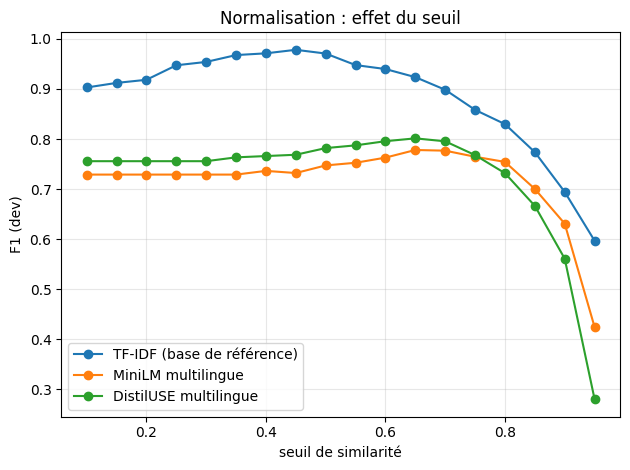

Méthode retenue : TF-IDF (base de référence) | seuil = 0.45


In [26]:
# Jeux d'évaluation de la normalisation
def typo(s, rng):
    if len(s) < 4:
        return s
    i = rng.randrange(1, len(s) - 1)
    op = rng.choice(["swap", "drop", "sub", "dup"])
    if op == "swap": return s[:i] + s[i + 1] + s[i] + s[i + 2:]
    if op == "drop": return s[:i] + s[i + 1:]
    if op == "sub":  return s[:i] + rng.choice(string.ascii_lowercase) + s[i + 1:]
    return s[:i] + s[i] + s[i:]

rng_n = random.Random(SEED)
pos_dev, pos_test = [], []
alias_pairs = [(a, c) for c, al in SKILL_ALIASES.items() for a in al]
for canon in SKILL_REFERENCE:
    for v in (canon.lower(), canon.replace(" ", "").replace("-", ""), typo(canon, rng_n)):
        if v != canon: pos_dev.append((v, canon))
    for v in (canon.upper(), typo(canon, rng_n)):
        if v != canon: pos_test.append((v, canon))
# les alias (sémantiques : « TALN » -> NLP) sont répartis entre dev et test, un sur deux
for k, pair in enumerate(alias_pairs):
    (pos_dev if k % 2 == 0 else pos_test).append(pair)
pos_dev, pos_test = list(dict.fromkeys(pos_dev)), list(dict.fromkeys(pos_test))

# « Négatifs » : fragments qui ne sont PAS des compétences (faux positifs possibles du NER)
NEGATIVES = (organizations + cities + ["Stage", "Internship", "Responsable", "Équipe", "Projet", "Master", "Licence",
             "Mars", "Juin", "Anglais", "Français", "Rapport", "Analyse", "Données", "Entreprise", "Candidat",
             "Université", "Ingénieur", "Développement", "Gestion"])
neg_dev, neg_test = NEGATIVES[0::2], NEGATIVES[1::2]
print(f"dev : {len(pos_dev)} positifs / {len(neg_dev)} négatifs | test : {len(pos_test)} positifs / {len(neg_test)} négatifs")

def norm_curve(norm, pos, neg, ths):
    ps = norm.scores([s for s, _ in pos]); ns = norm.scores(neg) if neg else []
    gold = [c for _, c in pos]
    rows = []
    for th in ths:
        tp = sum(1 for (c, sc), g in zip(ps, gold) if sc >= th and c == g)
        fp = sum(1 for (c, sc), g in zip(ps, gold) if sc >= th and c != g) + sum(1 for c, sc in ns if sc >= th)
        fn = len(gold) - tp
        P = tp / (tp + fp) if tp + fp else 0.0
        R = tp / (tp + fn) if tp + fn else 0.0
        rows.append({"seuil": round(float(th), 2), "precision": P, "recall": R,
                     "f1": 2 * P * R / (P + R) if P + R else 0.0})
    return pd.DataFrame(rows)

THS = np.arange(0.10, 0.96, 0.05)
curves_dev = {n: norm_curve(e, pos_dev, neg_dev, THS) for n, e in ENCODERS.items()}
best_th = {n: float(c.loc[c["f1"].idxmax(), "seuil"]) for n, c in curves_dev.items()}

rows = []
for n, e in ENCODERS.items():
    th = best_th[n]
    r_test = norm_curve(e, pos_test, neg_test, [th]).iloc[0]
    top = e.topk([s for s, _ in pos_test], 3)
    gold = [c for _, c in pos_test]
    rows.append({"méthode": n, "seuil choisi (dev)": th, "F1 dev": curves_dev[n]["f1"].max(),
                 "F1 test": r_test["f1"], "précision test": r_test["precision"], "rappel test": r_test["recall"],
                 "exactitude@1 (test)": np.mean([t[0] == g for t, g in zip(top, gold)]),
                 "exactitude@3 (test)": np.mean([g in t for t, g in zip(top, gold)])})
norm_results = pd.DataFrame(rows).set_index("méthode")
RESULTS["normalisation"] = norm_results
display(norm_results.round(3))

for n, c in curves_dev.items():
    plt.plot(c["seuil"], c["f1"], marker="o", label=n)
plt.xlabel("seuil de similarité"); plt.ylabel("F1 (dev)"); plt.title("Normalisation : effet du seuil")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

BEST_ENC = norm_results["F1 dev"].idxmax()
NORMALIZER, NORM_TH = ENCODERS[BEST_ENC], best_th[BEST_ENC]
print(f"Méthode retenue : {BEST_ENC} | seuil = {NORM_TH:.2f}")

In [27]:
# Exemples commentés : compétences mal rattachées (test)
ex = []
top1 = NORMALIZER.scores([s for s, _ in pos_test])
for (s, g), (c, sc) in zip(pos_test, top1):
    if c != g or sc < NORM_TH:
        ex.append({"surface": s, "attendu": g, "prédit": c, "similarité": round(sc, 3), "rejeté": sc < NORM_TH})
display(pd.DataFrame(ex).head(15))
print(f"{len(ex)} cas d'erreur ou de rejet sur {len(pos_test)}")

# Exploration (reprise de la première version) : compétences hors référence et paires très proches
unknown = sorted({s for lst in cvs_extracted_df["competences"] for s in lst} - set(SKILL_REFERENCE))
print("\nCompétences extraites absentes de la référence (faux positifs ou variantes) :", unknown[:20], f"({len(unknown)} au total)")
Sm = NORMALIZER.sim_matrix(SKILL_REFERENCE)
ref = SKILL_REFERENCE
pairs = [(ref[i], ref[j], Sm[i, j]) for i in range(len(ref)) for j in range(i + 1, len(ref)) if Sm[i, j] >= 0.8]
print(f"Paires de compétences de référence avec similarité >= 0.8 : {len(pairs)}")
display(pd.DataFrame(pairs, columns=["compétence 1", "compétence 2", "similarité"]).sort_values("similarité", ascending=False).head(15))

,surface,attendu,prédit,similarité,rejeté
0,HTLM,HTML,HTML,0.434,True
1,ML,Machine Learning,HTML,0.358,True
2,DL,Deep Learning,SQL,0.206,True
3,TALN,NLP,Talend,0.513,False
4,Natural Language Processing,NLP,Feature Engineering,0.301,True
5,Dataviz,Data Visualization,Data Visualization,0.381,True
6,Modélisation de données,Data Modeling,Data Visualization,0.399,True
7,Entrepôt de données,Data Warehousing,Deep Learning,0.171,True
8,DWH,Data Warehousing,PyTorch,0.199,True
9,TF,TensorFlow,Talend,0.200,True


11 cas d'erreur ou de rejet sur 119

Compétences extraites absentes de la référence (faux positifs ou variantes) : ['Analyse statistique', 'Data cleaning'] (2 au total)
Paires de compétences de référence avec similarité >= 0.8 : 0


,compétence 1,compétence 2,similarité


## 11. Score d'appariement CV–offre explicable

**Principe.** Le score est une **somme pondérée de critères** : chaque critère contribue à un nombre de points connu, ce qui rend l'explication exacte (pas d'approximation de type SHAP).

| Critère | Poids | Calcul |
|---|---|---|
| Compétences requises | 0,55 | part des compétences requises présentes dans le CV |
| Compétences appréciées | 0,20 | part des compétences appréciées présentes |
| Expérience | 0,10 | durée trouvée dans le CV / durée demandée (plafonnée à 1) |
| Diplôme | 0,15 | niveau du diplôme du CV / niveau demandé (`Bac+n`, plafonné à 1) |

Les compétences du CV passent par l'extraction NER puis la normalisation (partie 10). Trois scoreurs sont comparés : le pipeline (par extracteur), le pipeline avec **entités parfaites** (borne supérieure) et une **base de référence naïve** : similarité d'embeddings entre le texte brut du CV et la description de l'offre.

In [28]:
OFFERS_N, OFFER_IDS = {}, []
def parse_level(txt):
    m = re.search(r"Bac\s*\+\s*(\d)", txt)
    return int(m.group(1)) if m else 5

for _, o in offers_df.iterrows():
    OFFER_IDS.append(o["offer_id"])
    OFFERS_N[o["offer_id"]] = {
        "id": o["offer_id"], "title": o["position"], "profile": o["profile"], "text": o["description"],
        "required": list(dict.fromkeys(o["required_skills"])),
        "pref": [s for s in dict.fromkeys(o["preferred_skills"]) if s not in o["required_skills"]],
        "min_years": float(o["experience_required"]), "min_level": parse_level(o["degree"]),
    }
print(len(OFFER_IDS), "offres normalisées")
display(pd.DataFrame(OFFERS_N).T[["title", "profile", "required", "pref", "min_years", "min_level"]])

def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if not unicodedata.combining(c))

def degree_level(txt):
    t = strip_accents(txt.lower())
    if re.search(r"doctorat|phd", t): return 8
    if re.search(r"master|ingenieur|engineering", t): return 5
    if re.search(r"licence|bachelor|\bdut\b", t): return 3
    return 0

def experience_months(text):
    return float(sum(int(m) for m in re.findall(r"(\d+)\s*(?:mois|months?)", text, flags=re.IGNORECASE)))

def extract_profile(text, ents, normalizer, th, exact_only=False):
    surfaces = [text[s:e] for s, e, l in sorted(ents) if l == "COMPETENCE"]
    if exact_only:
        canon = [CANON_LOWER.get(s.lower()) for s in surfaces]
    else:
        canon = normalizer.map(surfaces, th) if surfaces else []
    level = max([degree_level(text[s:e]) for s, e, l in ents if l == "DIPLOME"] or [0])
    return {"skills": {c for c in canon if c}, "level": level, "years": experience_months(text) / 12.0}

W_DEFAULT = {"req": 0.55, "pref": 0.20, "exp": 0.10, "deg": 0.15}

def match_score(profile, offer, W=W_DEFAULT):
    items = []
    for s in offer["required"]:
        pts = W["req"] / len(offer["required"]) * (s in profile["skills"])
        items.append({"critère": s, "type": "requis", "présent": s in profile["skills"], "points": pts, "max": W["req"] / len(offer["required"])})
    for s in offer["pref"]:
        pts = W["pref"] / len(offer["pref"]) * (s in profile["skills"])
        items.append({"critère": s, "type": "apprécié", "présent": s in profile["skills"], "points": pts, "max": W["pref"] / len(offer["pref"])})
    e = min(1.0, profile["years"] / offer["min_years"]) if offer["min_years"] > 0 else 1.0
    items.append({"critère": "expérience", "type": "expérience", "présent": e > 0, "points": W["exp"] * e, "max": W["exp"]})
    d = min(1.0, profile["level"] / offer["min_level"]) if offer["min_level"] > 0 else 1.0
    items.append({"critère": "diplôme", "type": "diplôme", "présent": d > 0, "points": W["deg"] * d, "max": W["deg"]})
    return sum(i["points"] for i in items), items

def pipeline_scores(texts, ents_list, normalizer, th, exact_only=False, W=W_DEFAULT):
    profs = [extract_profile(t, e, normalizer, th, exact_only) for t, e in zip(texts, ents_list)]
    S = np.array([[match_score(p, OFFERS_N[o], W)[0] for o in OFFER_IDS] for p in profs])
    return S, profs

# vérification : un profil parfait obtient 1.0
_perfect = {"skills": set(OFFERS_N[OFFER_IDS[0]]["required"] + OFFERS_N[OFFER_IDS[0]]["pref"]), "level": 8, "years": 10}
assert abs(match_score(_perfect, OFFERS_N[OFFER_IDS[0]])[0] - 1.0) < 1e-9
print("Score vérifié (profil parfait = 1.0).")

10 offres normalisées


,title,profile,required,pref,min_years,min_level
OFF001,Data Analyst Junior – Analyse et reporting,Data Analyst,"[Python, SQL, Pandas, Power BI, Excel]","[Tableau, Matplotlib, Statistiques]",0.0,5
OFF002,Data Analyst – Analyse décisionnelle,Data Analyst,"[SQL, Python, Excel, Power BI, Statistiques]","[Tableau, DAX, ETL]",1.0,5
OFF003,Data Scientist Junior – Modélisation prédictive,Data Scientist,"[Python, Scikit-learn, Pandas, Machine Learning, NumPy]","[TensorFlow, Deep Learning, MLflow]",0.0,5
OFF004,Data Scientist – Intelligence artificielle,Data Scientist,"[Python, TensorFlow, Deep Learning, Machine Learning, NLP]","[PyTorch, Transformers, Hugging Face]",1.0,5
OFF005,Data Engineer Junior – Pipelines de données,Data Engineer,"[Python, SQL, Apache Spark, ETL, PostgreSQL]","[Airflow, Docker, Git]",0.0,5
OFF006,Data Engineer – Architecture Big Data,Data Engineer,"[Python, Apache Spark, SQL, Hadoop, Data Warehousing]","[Kafka, Databricks, Cloud]",2.0,5
OFF007,Développeur Full Stack Junior,Développeur Web,"[JavaScript, React, Node.js, HTML, CSS]","[MongoDB, Git, REST API]",0.0,5
OFF008,Développeur Backend – Applications web,Développeur Web,"[Python, Django, SQL, REST API, PostgreSQL]","[Docker, Git, Linux]",1.0,5
OFF009,Business Intelligence Analyst Junior,BI Analyst,"[Power BI, SQL, DAX, Excel, Data Visualization]","[Power Query, ETL, Talend]",0.0,5
OFF010,BI Analyst – Reporting et pilotage,BI Analyst,"[Power BI, SQL, ETL, Data Warehousing, Excel]","[Talend, Oracle, DAX]",2.0,5


Score vérifié (profil parfait = 1.0).


In [29]:
# Scores sur le jeu de test pour tous les scoreurs
TEST_TEXTS = [r["text"] for r in TEST]
ENTS_TEST = {name: fn(TEST_TEXTS) for name, fn in NER_FNS.items()}

S_STRUCT, PROFS = {}, {}
for name, ents in ENTS_TEST.items():
    S_STRUCT[name], PROFS[name] = pipeline_scores(TEST_TEXTS, ents, NORMALIZER, NORM_TH)
S_GOLD, PROFS["gold"] = pipeline_scores(TEST_TEXTS, [set(map(tuple, r["entities"])) for r in TEST], NORMALIZER, NORM_TH)

OFFER_EMB = np.asarray(EMB.encode([OFFERS_N[o]["text"] for o in OFFER_IDS], normalize_embeddings=True, show_progress_bar=False))
def naive_scores(texts):
    T = np.asarray(EMB.encode(list(texts), normalize_embeddings=True, batch_size=16, show_progress_bar=False))
    return T @ OFFER_EMB.T
S_NAIVE = naive_scores(TEST_TEXTS)
print("Scores calculés pour :", list(S_STRUCT) + ["gold", "naïf (embeddings)"])

Scores calculés pour : ['spacy', 'camembert', 'gold', 'naïf (embeddings)']


### 11.1 Explication du score : quelles compétences expliquent le résultat ?

Offre : Data Scientist – Intelligence artificielle (OFF004)
Requis : ['Python', 'TensorFlow', 'Deep Learning', 'Machine Learning', 'NLP'] | Appréciés : ['PyTorch', 'Transformers', 'Hugging Face']


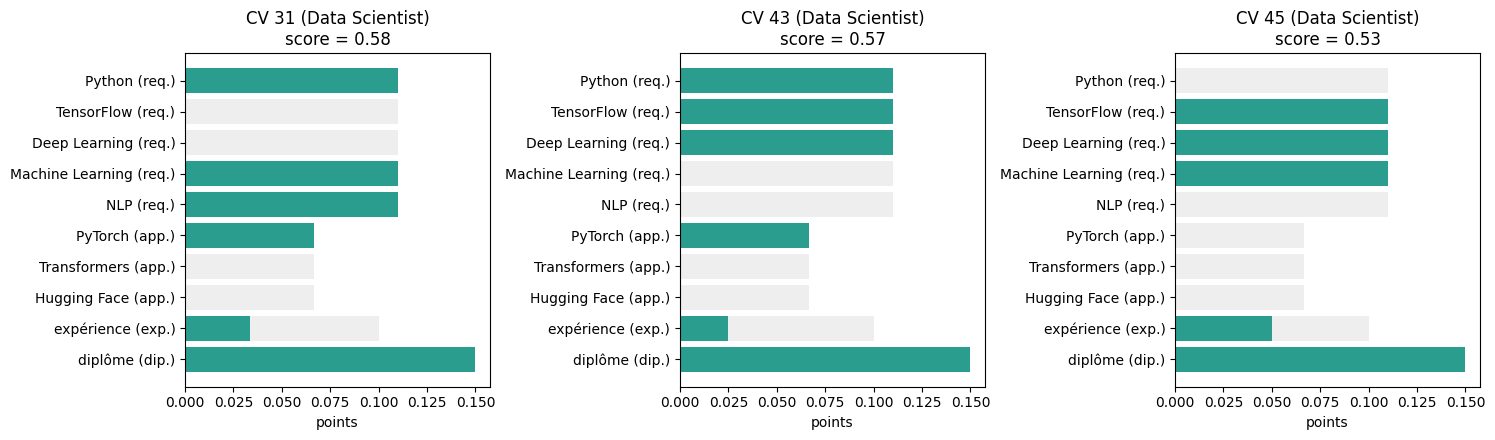


CV 31 — compétences requises présentes : ['Python', 'Machine Learning', 'NLP']
Compétences requises manquantes : ['TensorFlow', 'Deep Learning']
Vérification d'additivité (retrait d'une compétence) : OK


In [30]:
SCORER_EXPL = EXTRACTOR_NAME
j_expl = OFFER_IDS.index("OFF004") if "OFF004" in OFFER_IDS else 0
offer = OFFERS_N[OFFER_IDS[j_expl]]
order = np.argsort(-S_STRUCT[SCORER_EXPL][:, j_expl])[:3]
print(f"Offre : {offer['title']} ({offer['id']})")
print("Requis :", offer["required"], "| Appréciés :", offer["pref"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, i in zip(axes, order):
    total, items = match_score(PROFS[SCORER_EXPL][i], offer)
    df = pd.DataFrame(items)
    colors = df["présent"].map({True: "#2a9d8f", False: "#d9d9d9"})
    ax.barh(df["critère"] + " (" + df["type"].str[:3] + ".)", df["max"], color="#eeeeee")
    ax.barh(df["critère"] + " (" + df["type"].str[:3] + ".)", df["points"], color=colors)
    ax.invert_yaxis(); ax.set_title(f"CV {TEST[i]['cv_id']} ({TEST[i]['profile']})\nscore = {total:.2f}")
    ax.set_xlabel("points")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "explication_score.png", dpi=150); plt.show()

# Compétences qui expliquent / manquent pour le meilleur candidat
i = order[0]
prof = PROFS[SCORER_EXPL][i]
print(f"\nCV {TEST[i]['cv_id']} — compétences requises présentes :", [s for s in offer["required"] if s in prof["skills"]])
print("Compétences requises manquantes :", [s for s in offer["required"] if s not in prof["skills"]])

# Vérification d'additivité : retirer une compétence fait baisser le score exactement de sa contribution
total, items = match_score(prof, offer)
for it in items:
    if it["type"] in ("requis", "apprécié") and it["présent"]:
        reduced = {**prof, "skills": prof["skills"] - {it["critère"]}}
        assert abs((total - match_score(reduced, offer)[0]) - it["points"]) < 1e-9
print("Vérification d'additivité (retrait d'une compétence) : OK")

## 12. Validation du classement

Pour chaque offre, **8 candidats** du jeu de test (4 du profil visé, 4 d'autres profils) sont classés, soit **80 paires (offre, CV)**. Le classement du système est comparé à un **classement de référence établi à la main par le groupe** au moyen de :
- la corrélation de **Spearman** et le **tau de Kendall** ;
- le **NDCG@5**.

**Classement manuel.** Chaque paire a reçu une note de 0 à 10 (`manual_score`), attribuée par le groupe à partir de la lecture du CV et de l'offre, sans consulter les scores du système. Les notes sont enregistrées dans `data/processed/manual_ranking.csv`, et la source de la référence utilisée est affichée par la cellule de calcul (`REF_SOURCE`).

**Précaution d'interprétation.** Les critères du groupe (compétences requises, poste visé, diplôme) recoupent ceux du score du système : les notes manuelles sont corrélées de 0,87 à 0,99 avec le nombre de compétences requises présentes. Les corrélations obtenues sont donc **élevées par construction** et mesurent l'accord du système avec un jugement humain proche de ses propres critères, pas une validation indépendante.

*Le notebook prévoit, en l'absence du fichier manuel, un classement de référence simulé (score calculé sur les compétences attribuées lors de la génération, plus un bruit gaussien). Il ne sert qu'à tester le code et n'est pas utilisé pour les résultats rapportés.*

In [31]:
N_CAND, N_SAME = 8, 4
rng_c = random.Random(SEED)
CAND = {}
for j, oid in enumerate(OFFER_IDS):
    prof = OFFERS_N[oid]["profile"]
    same = [i for i, r in enumerate(TEST) if r["profile"] == prof]
    other = [i for i, r in enumerate(TEST) if r["profile"] != prof]
    k = min(N_SAME, len(same))
    CAND[j] = sorted(rng_c.sample(same, k) + rng_c.sample(other, min(N_CAND - k, len(other))))

cv_row = cvs_df.set_index("cv_id")

# Modèles de fichiers pour le classement manuel
tmpl = [{"offer_id": OFFER_IDS[j], "cv_id": TEST[i]["cv_id"], "manual_score": ""} for j, idxs in CAND.items() for i in idxs]
pd.DataFrame(tmpl).to_csv(DATA_PROCESSED / "manual_ranking_template.csv", index=False, encoding="utf-8-sig")
pd.DataFrame([{"cv_id": r["cv_id"], "cv_text": r["text"]} for r in TEST]).to_csv(
    DATA_PROCESSED / "cv_texts_for_ranking.csv", index=False, encoding="utf-8-sig")

MANUAL_PATH = DATA_PROCESSED / "manual_ranking.csv"
REF = {}
if MANUAL_PATH.exists():
    man = pd.read_csv(MANUAL_PATH, encoding="utf-8-sig")
    pos_of = {r["cv_id"]: i for i, r in enumerate(TEST)}
    off_of = {o: j for j, o in enumerate(OFFER_IDS)}
    for _, r in man.iterrows():
        if pd.notna(r["manual_score"]) and str(r["manual_score"]).strip() != "":
            REF[(off_of[r["offer_id"]], pos_of[int(r["cv_id"])])] = float(r["manual_score"])
    REF_SOURCE = "classement manuel du groupe"
else:
    rng_ref = np.random.default_rng(SEED)
    for j, idxs in CAND.items():
        for i in idxs:
            row = cv_row.loc[TEST[i]["cv_id"]]
            latent = {"skills": set(row["skills"]), "level": degree_level(row["degree"]),
                      "years": experience_months(row["experience"]) / 12.0}
            REF[(j, i)] = max(0.0, match_score(latent, OFFERS_N[OFFER_IDS[j]])[0] + rng_ref.normal(0, 0.05))
    REF_SOURCE = "SIMULÉ (proxy) — à remplacer par le classement manuel"
print("Référence utilisée :", REF_SOURCE, "|", len(REF), "notes")

Référence utilisée : classement manuel du groupe | 80 notes


In [32]:
from sklearn.metrics import ndcg_score

def rank_report(S, name):
    rows = []
    for j, idxs in CAND.items():
        pairs = [(S[i, j], REF[(j, i)]) for i in idxs if (j, i) in REF]
        if len(pairs) < 3: continue
        sv, rv = np.array([p[0] for p in pairs]), np.array([p[1] for p in pairs])
        rho = stats.spearmanr(sv, rv)[0] if sv.std() > 0 and rv.std() > 0 else np.nan
        tau = stats.kendalltau(sv, rv)[0] if sv.std() > 0 and rv.std() > 0 else np.nan
        rows.append({"rho": rho, "tau": tau, "ndcg5": ndcg_score(rv[None, :].clip(0), sv[None, :], k=5)})
    d = pd.DataFrame(rows)
    return {"scoreur": name, "Spearman": d["rho"].mean(), "Kendall": d["tau"].mean(), "NDCG@5": d["ndcg5"].mean(), "offres": len(d)}

rank_rows = [rank_report(S_STRUCT[n], f"pipeline ({n})") for n in S_STRUCT]
rank_rows += [rank_report(S_GOLD, "pipeline (entités parfaites)"), rank_report(S_NAIVE, "naïf (embeddings du texte brut)")]
ranking_df = pd.DataFrame(rank_rows).set_index("scoreur")
RESULTS["classement"] = ranking_df
print("Référence :", REF_SOURCE)
display(ranking_df.round(3))

Référence : classement manuel du groupe


,Spearman,Kendall,NDCG@5,offres
scoreur,,,,
pipeline (spacy),0.960,0.915,0.987,10
pipeline (camembert),0.960,0.915,0.987,10
pipeline (entités parfaites),0.960,0.915,0.987,10
naïf (embeddings du texte brut),0.801,0.663,0.956,10


In [33]:
# Étude de sensibilité : poids du score (extracteur retenu)
W_SETS = {
    "par défaut (0.55 / 0.20 / 0.10 / 0.15)": W_DEFAULT,
    "compétences seules (0.70 / 0.30 / 0 / 0)": {"req": 0.70, "pref": 0.30, "exp": 0.0, "deg": 0.0},
    "sans compétences appréciées (0.70 / 0 / 0.15 / 0.15)": {"req": 0.70, "pref": 0.0, "exp": 0.15, "deg": 0.15},
    "forte expérience (0.40 / 0.10 / 0.30 / 0.20)": {"req": 0.40, "pref": 0.10, "exp": 0.30, "deg": 0.20},
}
rows = []
for label, W in W_SETS.items():
    S_w, _ = pipeline_scores(TEST_TEXTS, ENTS_TEST[EXTRACTOR_NAME], NORMALIZER, NORM_TH, W=W)
    rows.append(rank_report(S_w, label))
sens_df = pd.DataFrame(rows).set_index("scoreur")
RESULTS["sensibilite_poids"] = sens_df
display(sens_df.round(3))

,Spearman,Kendall,NDCG@5,offres
scoreur,,,,
par défaut (0.55 / 0.20 / 0.10 / 0.15),0.960,0.915,0.987,10
compétences seules (0.70 / 0.30 / 0 / 0),0.969,0.931,0.986,10
sans compétences appréciées (0.70 / 0 / 0.15 / 0.15),0.899,0.817,0.963,10
forte expérience (0.40 / 0.10 / 0.30 / 0.20),0.954,0.900,0.982,10


## 13. Audit d'équité et mitigation (apports 1 et 2)

**Question.** Le score change-t-il quand on modifie le **prénom** ou le **genre** dans un CV par ailleurs identique ?

**Méthode : CV jumeaux.** Pour chaque CV de `dev` + `test`, on fabrique six jumeaux qui ne diffèrent que par l'identité du candidat : prénoms **marocains, français et anglo-saxons**, féminins et masculins, avec une civilité (« Mme », « M. », « Ms », « Mr »). Le reste du texte est strictement identique.

**Deux scoreurs audités :**
- **A — pipeline structuré** (NER → normalisation → score) : n'utilise jamais le nom, mais le NER pourrait être perturbé par certains prénoms ;
- **B — score naïf** (embeddings du texte brut du CV) : le nom fait partie du texte, un biais est donc possible.

**Mesures.** Écart de score par rapport au groupe de référence `FR_M` (test de Wilcoxon apparié, intervalle de confiance bootstrap, correction de Bonferroni), exprimé en **écarts-types** (`z`) pour comparer les scoreurs ; taux de **faux positifs du NER sur le nom** ; **taux de sélection** dans un panel mélangé (règle des 4/5).

**Mitigation (apport 1).** On teste quatre niveaux d'anonymisation : aucune, civilité seule, noms connus seuls, complète. Le dictionnaire de noms connus ne couvre volontairement que **6 prénoms/noms sur 8 par groupe** pour simuler une couverture imparfaite.

In [41]:
NAME_POOLS = {
    "MA_F": (["Fatima", "Khadija", "Salma", "Imane", "Meryem", "Sara", "Zineb", "Asmae"],
             ["Alami", "Bennani", "Tazi", "Idrissi", "Fassi", "Berrada", "Chraibi", "Lahlou"]),
    "MA_M": (["Youssef", "Mohamed", "Hamza", "Omar", "Karim", "Amine", "Yassine", "Mehdi"],
             ["Alami", "Bennani", "Tazi", "Idrissi", "Fassi", "Berrada", "Chraibi", "Lahlou"]),
    "FR_F": (["Camille", "Léa", "Marie", "Julie", "Claire", "Sophie", "Chloé", "Manon"],
             ["Martin", "Bernard", "Dubois", "Moreau", "Laurent", "Simon", "Michel", "Lefebvre"]),
    "FR_M": (["Julien", "Thomas", "Nicolas", "Antoine", "Maxime", "Pierre", "Lucas", "Hugo"],
             ["Martin", "Bernard", "Dubois", "Moreau", "Laurent", "Simon", "Michel", "Lefebvre"]),
    "EN_F": (["Emily", "Sarah", "Jessica", "Laura", "Olivia", "Hannah", "Megan", "Rachel"],
             ["Smith", "Johnson", "Brown", "Taylor", "Wilson", "Davies", "Evans", "Walker"]),
    "EN_M": (["James", "John", "Michael", "David", "Daniel", "Matthew", "Ryan", "Andrew"],
             ["Smith", "Johnson", "Brown", "Taylor", "Wilson", "Davies", "Evans", "Walker"]),
}
CIVILITY = {"MA_F": "Mme", "FR_F": "Mme", "EN_F": "Ms", "MA_M": "M.", "FR_M": "M.", "EN_M": "Mr"}
GROUPS, REF_GROUP = list(NAME_POOLS), "FR_M"
AUDIT_RECS = DEV + TEST

def make_twin(rec, group):
    rr = random.Random(f"{rec['cv_id']}-{group}")
    firsts, lasts = NAME_POOLS[group]
    name = f"{rr.choice(firsts)} {rr.choice(lasts)}"
    full = f"{CIVILITY[group]} {name}"
    text = rec["text"]
    text = text.replace(rec["name"], full) if rec["name"] in text else full + "\n" + text
    return text, name

TWIN = {(i, g): make_twin(rec, g) for i, rec in enumerate(AUDIT_RECS) for g in GROUPS}
i0 = 0
print(f"{len(AUDIT_RECS)} CV x {len(GROUPS)} groupes = {len(TWIN)} jumeaux")
print("\nExemple (début de texte) :")
for g in ["MA_F", "FR_M", "EN_F"]:
    print(f"[{g}]", TWIN[(i0, g)][0][:110].replace("\n", " ⏎ "))

46 CV x 6 groupes = 276 jumeaux

Exemple (début de texte) :
[MA_F] CURRICULUM VITAE ⏎  ⏎ Mme Salma Chraibi ⏎ Poste recherché / Target position: Développeur Web ⏎  ⏎ PROFIL / PROFESSIONAL 
[FR_M] CURRICULUM VITAE ⏎  ⏎ M. Pierre Simon ⏎ Poste recherché / Target position: Développeur Web ⏎  ⏎ PROFIL / PROFESSIONAL SU
[EN_F] CURRICULUM VITAE ⏎  ⏎ Ms Jessica Davies ⏎ Poste recherché / Target position: Développeur Web ⏎  ⏎ PROFIL / PROFESSIONAL 


In [42]:
# ----------------------------------------------------------------- anonymiseurs (mitigation)
KNOWN_FIRST = sorted({n for f, _ in NAME_POOLS.values() for n in f[:6]})
KNOWN_LAST = sorted({n for _, l in NAME_POOLS.values() for n in l[:6]})
KNOWN_RE = re.compile(r"\b(?:%s)(?:[ \t]+(?:%s))*\b" % ("|".join(map(re.escape, KNOWN_FIRST + KNOWN_LAST)),
                                                       "|".join(map(re.escape, KNOWN_FIRST + KNOWN_LAST))))
CIV_RE = re.compile(r"\b(?:Mme|Mrs|Mr|Ms|M\.)[ \t]+")
CIV_NAME_RE = re.compile(r"\b(?:Mme|Mrs|Mr|Ms|M\.)[ \t]+[A-ZÀ-Ý][\w'’-]+(?:[ \t]+[A-ZÀ-Ý][\w'’-]+)?")

ANONYMIZERS = {
    "aucune": lambda t: t,
    "civilité seule": lambda t: CIV_RE.sub("", t),
    "noms connus seuls": lambda t: KNOWN_RE.sub("[CANDIDAT]", t),
    "complète": lambda t: KNOWN_RE.sub("[CANDIDAT]", CIV_NAME_RE.sub("[CANDIDAT]", t)),
}
for k, f in ANONYMIZERS.items():
    print(f"{k:20s} ->", f(TWIN[(0, 'MA_F')][0])[:70].replace("\n", " ⏎ "))

aucune               -> CURRICULUM VITAE ⏎  ⏎ Mme Salma Chraibi ⏎ Poste recherché / Target position:
civilité seule       -> CURRICULUM VITAE ⏎  ⏎ Salma Chraibi ⏎ Poste recherché / Target position: Dév
noms connus seuls    -> CURRICULUM VITAE ⏎  ⏎ Mme [CANDIDAT] Chraibi ⏎ Poste recherché / Target posi
complète             -> CURRICULUM VITAE ⏎  ⏎ [CANDIDAT] ⏎ Poste recherché / Target position: Dévelo


In [43]:
_audit_model = NER_FNS[EXTRACTOR_NAME]
_ner_cache = {}
def AUDIT_NER(texts):
    """NER avec cache : les textes identiques (cas de l'anonymisation complète) ne sont traités qu'une fois."""
    todo = [t for t in dict.fromkeys(texts) if t not in _ner_cache]
    if todo:
        for t, e in zip(todo, _audit_model(todo)):
            _ner_cache[t] = e
    return [_ner_cache[t] for t in texts]

rng_audit = np.random.default_rng(SEED)

def locate(text, needles):
    return [(m.start(), m.end()) for n in needles for m in re.finditer(re.escape(n), text)]

def run_audit(transform):
    texts, meta = [], []
    for g in GROUPS:
        for i in range(len(AUDIT_RECS)):
            t, name = TWIN[(i, g)]
            texts.append(transform(t)); meta.append((g, name))
    ents = AUDIT_NER(texts)
    S_flat, _ = pipeline_scores(texts, ents, NORMALIZER, NORM_TH)
    n, G, O = len(AUDIT_RECS), len(GROUPS), len(OFFER_IDS)
    S_A = S_flat.reshape(G, n, O).transpose(1, 0, 2)
    S_B = naive_scores(texts).reshape(G, n, O).transpose(1, 0, 2)
    fp = {g: [] for g in GROUPS}
    for t, e, (g, name) in zip(texts, ents, meta):
        spans = locate(t, [name, "[CANDIDAT]"])
        if spans:
            fp[g].append(any(s < b and a < e2 for (s, e2, _) in e for (a, b) in spans))
    return {"A": S_A, "B": S_B, "fp": {g: (np.mean(v) if v else np.nan) for g, v in fp.items()}}

def audit_table(S, label):
    per_cv = S.mean(axis=2)
    ref = per_cv[:, GROUPS.index(REF_GROUP)]
    sd = max(ref.std(ddof=1), 1e-9)
    rows = []
    for gi, g in enumerate(GROUPS):
        if g == REF_GROUP: continue
        d = per_cv[:, gi] - ref
        boots = [rng_audit.choice(d, len(d)).mean() for _ in range(1000)]
        try:
            p = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
        except ValueError:
            p = 1.0
        rows.append({"scoreur": label, "groupe": g, "écart moyen": d.mean(), "écart (z)": d.mean() / sd,
                     "IC95 bas": np.percentile(boots, 2.5), "IC95 haut": np.percentile(boots, 97.5),
                     "p (Wilcoxon)": p, "p (Bonferroni)": min(1.0, p * (len(GROUPS) - 1))})
    return pd.DataFrame(rows)

def gap_summary(S):
    per_cv = S.mean(axis=2)
    sd = max(per_cv[:, GROUPS.index(REF_GROUP)].std(ddof=1), 1e-9)
    F = [i for i, g in enumerate(GROUPS) if g.endswith("_F")]; M = [i for i, g in enumerate(GROUPS) if g.endswith("_M")]
    gender = per_cv[:, F].mean(1) - per_cv[:, M].mean(1)
    org = {o: per_cv[:, [i for i, g in enumerate(GROUPS) if g.startswith(o)]].mean() for o in ("MA", "FR", "EN")}
    try:
        p_gender = stats.wilcoxon(gender).pvalue if np.any(gender != 0) else 1.0
    except ValueError:
        p_gender = 1.0
    return {"écart max entre groupes (z)": np.mean(per_cv.max(1) - per_cv.min(1)) / sd,
            "écart genre F-M (z)": gender.mean() / sd, "p genre": p_gender,
            "écart origine max (z)": (max(org.values()) - min(org.values())) / sd}

def selection_rates(S, frac=0.25, reps=300):
    n, G, O = S.shape
    k = max(1, int(round(frac * n)))
    sel, cnt = np.zeros(G), np.zeros(G)
    for _ in range(reps):
        assign = rng_audit.integers(0, G, size=n)
        for j in range(O):
            s = S[np.arange(n), assign, j]
            top = np.argsort(-s)[:k]
            for g in range(G):
                members = np.where(assign == g)[0]
                if len(members):
                    sel[g] += np.isin(members, top).sum(); cnt[g] += len(members)
    rates = sel / np.maximum(cnt, 1)
    return dict(zip(GROUPS, rates)), (rates.min() / rates.max() if rates.max() > 0 else np.nan)

AUDIT = {name: run_audit(fn) for name, fn in ANONYMIZERS.items()}
print("Audit calculé pour :", list(AUDIT))

Audit calculé pour : ['aucune', 'civilité seule', 'noms connus seuls', 'complète']


,scoreur,groupe,écart moyen,écart (z),IC95 bas,IC95 haut,p (Wilcoxon),p (Bonferroni)
0,A — pipeline structuré,MA_F,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
1,A — pipeline structuré,MA_M,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
2,A — pipeline structuré,FR_F,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
3,A — pipeline structuré,EN_F,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
4,A — pipeline structuré,EN_M,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
5,B — score naïf,MA_F,0.0059,0.1230,-0.0022,0.0135,0.0473,0.2365
6,B — score naïf,MA_M,0.0009,0.0188,-0.0048,0.0064,0.6415,1.0000
7,B — score naïf,FR_F,0.0068,0.1423,0.0018,0.0117,0.0279,0.1396
8,B — score naïf,EN_F,0.0024,0.0503,-0.0035,0.0084,0.3856,1.0000
9,B — score naïf,EN_M,-0.0020,-0.0414,-0.0076,0.0036,0.6415,1.0000


,FP NER sur le nom
groupe,
MA_F,0.000
MA_M,0.000
FR_F,0.109
FR_M,0.413
EN_F,0.435
EN_M,0.500


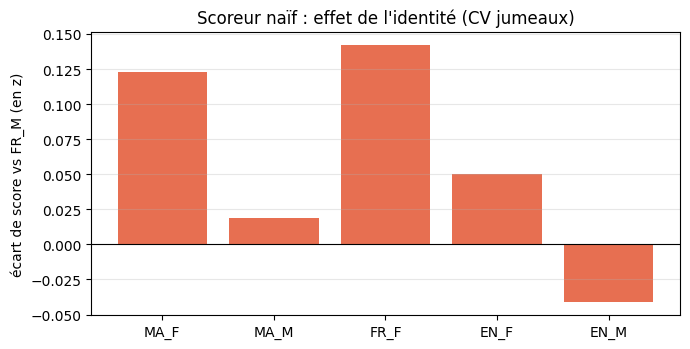

Taux de sélection (top 25 %) — pipeline A : {'MA_F': np.float64(0.266), 'MA_M': np.float64(0.255), 'FR_F': np.float64(0.264), 'FR_M': np.float64(0.256), 'EN_F': np.float64(0.263), 'EN_M': np.float64(0.262)} | ratio min/max : 0.959
Taux de sélection (top 25 %) — naïf B     : {'MA_F': np.float64(0.27), 'MA_M': np.float64(0.257), 'FR_F': np.float64(0.276), 'FR_M': np.float64(0.254), 'EN_F': np.float64(0.254), 'EN_M': np.float64(0.254)} | ratio min/max : 0.918
Règle des 4/5 : un ratio < 0.80 signale un impact disparate potentiel (à interpréter avec prudence vu la taille de l'échantillon).


In [44]:
# ---- 13.1 Situation initiale (sans anonymisation)
base = AUDIT["aucune"]
t_A, t_B = audit_table(base["A"], "A — pipeline structuré"), audit_table(base["B"], "B — score naïf")
audit_base = pd.concat([t_A, t_B], ignore_index=True)
RESULTS["audit_equite_base"] = audit_base
display(audit_base.round(4))

# taux de faux positifs du NER sur le nom (par groupe)
fp_df = pd.DataFrame({"groupe": GROUPS, "FP NER sur le nom": [base["fp"][g] for g in GROUPS]}).set_index("groupe")
display(fp_df.round(3))

# écarts par groupe (IC95) pour le scoreur naïf
tb = t_B.set_index("groupe")
plt.figure(figsize=(7, 3.6))
plt.bar(tb.index, tb["écart (z)"], color="#e76f51")
plt.axhline(0, color="k", lw=.8); plt.ylabel("écart de score vs FR_M (en z)")
plt.title("Scoreur naïf : effet de l'identité (CV jumeaux)"); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "audit_naif.png", dpi=150); plt.show()

# règle des 4/5 sur un panel mélangé (top 25 % par offre)
rates_A, di_A = selection_rates(base["A"]); rates_B, di_B = selection_rates(base["B"])
print("Taux de sélection (top 25 %) — pipeline A :", {g: round(v, 3) for g, v in rates_A.items()}, "| ratio min/max :", round(di_A, 3))
print("Taux de sélection (top 25 %) — naïf B     :", {g: round(v, 3) for g, v in rates_B.items()}, "| ratio min/max :", round(di_B, 3))
print("Règle des 4/5 : un ratio < 0.80 signale un impact disparate potentiel (à interpréter avec prudence vu la taille de l'échantillon).")

,anonymisation,scoreur,écart max entre groupes (z),écart genre F-M (z),p genre,écart origine max (z),FP NER sur le nom (moyen)
0,aucune,A — pipeline,0.0000,0.0000,1.0000,0.0000,0.2428
1,aucune,B — naïf,0.6932,0.1127,0.0000,0.0667,0.2428
2,civilité seule,A — pipeline,0.0000,0.0000,1.0000,0.0000,0.2174
3,civilité seule,B — naïf,0.7564,0.0528,0.0486,0.1415,0.2174
4,noms connus seuls,A — pipeline,0.0000,0.0000,1.0000,0.0000,0.0362
5,noms connus seuls,B — naïf,0.5572,0.0778,0.0046,0.1337,0.0362
6,complète,A — pipeline,0.0000,0.0000,1.0000,0.0000,0.0000
7,complète,B — naïf,0.0000,-0.0000,0.1797,0.0000,0.0000


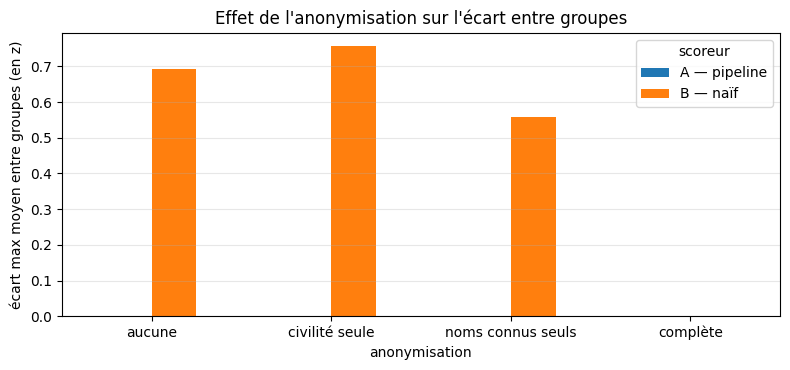

Part des CV où le nom est encore lisible après anonymisation : {'aucune': 1.0, 'civilité seule': 1.0, 'noms connus seuls': 0.043, 'complète': 0.0}


In [45]:
# ---- 13.2 Mitigation : que corrige chaque niveau d'anonymisation ?
rows = []
for name, res in AUDIT.items():
    for scorer, key in (("A — pipeline", "A"), ("B — naïf", "B")):
        gs = gap_summary(res[key])
        rows.append({"anonymisation": name, "scoreur": scorer, **gs,
                     "FP NER sur le nom (moyen)": np.nanmean(list(res["fp"].values()))})
mitig = pd.DataFrame(rows)
RESULTS["mitigation_equite"] = mitig
display(mitig.round(4))

piv = mitig.pivot(index="anonymisation", columns="scoreur", values="écart max entre groupes (z)").loc[list(ANONYMIZERS)]
piv.plot(kind="bar", figsize=(8, 3.8), rot=0)
plt.ylabel("écart max moyen entre groupes (en z)"); plt.title("Effet de l'anonymisation sur l'écart entre groupes")
plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.savefig(FIGURES_DIR / "mitigation_equite.png", dpi=150); plt.show()

# fuite résiduelle de l'anonymisation : noms encore présents après masquage
leak = {}
for name, f in ANONYMIZERS.items():
    remaining = sum(bool(re.search(re.escape(TWIN[(i, g)][1]), f(TWIN[(i, g)][0]))) for i in range(len(AUDIT_RECS)) for g in GROUPS)
    leak[name] = remaining / len(TWIN)
print("Part des CV où le nom est encore lisible après anonymisation :", {k: round(v, 3) for k, v in leak.items()})

## 14. Robustesse au bruit (apport 3)

Les CV réels passent par des PDF, de l'OCR et des saisies approximatives. On dégrade les CV de test avec trois types de bruit qui **conservent la longueur du texte** (les positions des entités de référence restent donc valides) :

| Bruit | Description | Niveaux |
|---|---|---|
| `accents` | suppression des accents | 0 → 100 % des caractères accentués |
| `ocr` | confusions de type OCR (`l→1`, `o→0`, `e→c`…) | 0 → 60 % des caractères concernés |
| `typo` | remplacement aléatoire de lettres | 0 → 15 % des lettres |

**Trois mesures :** F1 de l'extraction, **stabilité du classement** (Spearman entre classement propre et bruité), et **apport de la normalisation** : classement obtenu avec rattachement par embeddings vs rattachement exact seul. On teste aussi des modèles **entraînés avec du bruit** (`+aug`).

In [46]:
OCR_MAP = {"l": "1", "I": "l", "O": "0", "o": "0", "S": "5", "B": "8", "e": "c", "a": "o"}

def strip_accent_char(c):
    base = "".join(ch for ch in unicodedata.normalize("NFD", c) if not unicodedata.combining(ch))
    return base if len(base) == 1 else c

def perturb(text, mode, p, seed):
    rng = random.Random(seed)
    out = []
    for c in text:
        if c in " \n\t":
            out.append(c); continue
        r = rng.random()
        if mode == "accents": out.append(strip_accent_char(c) if r < p else c)
        elif mode == "ocr":   out.append(OCR_MAP.get(c, c) if r < p else c)
        elif mode == "typo":  out.append(rng.choice(string.ascii_lowercase) if (c.isalpha() and r < p) else c)
        else: raise ValueError(mode)
    s = "".join(out)
    assert len(s) == len(text), "la perturbation doit conserver la longueur"
    return s

NOISE_GRID = {"accents": [0, 0.5, 1.0], "ocr": [0, 0.1, 0.3, 0.6], "typo": [0, 0.03, 0.08, 0.15]}

demo = TEST[0]["text"][TEST[0]["text"].find("COMP"):][:150]
print("Original :", demo.replace("\n", " ⏎ "))
for mode, p in (("accents", 1.0), ("ocr", 0.3), ("typo", 0.08)):
    print(f"{mode:8s} p={p}:", perturb(demo, mode, p, SEED).replace("\n", " ⏎ "))

Original : s
accents  p=1.0: s
ocr      p=0.3: s
typo     p=0.08: s


In [47]:
# Entraînement avec bruit (augmentation) : original + une copie dégradée de chaque CV d'entraînement
def augment_records(recs, seed=SEED):
    rng = random.Random(seed)
    out = []
    for k, r in enumerate(recs):
        mode = rng.choice(["accents", "ocr", "typo"])
        p = {"accents": 0.5, "ocr": 0.15, "typo": 0.05}[mode]
        out.append({**r, "text": perturb(r["text"], mode, p, seed * 1000 + k)})
    return out

TRAIN_AUG = TRAIN + augment_records(TRAIN)
print("CV d'entraînement avec bruit :", len(TRAIN_AUG), "(dont", len(TRAIN), "propres)")

if RUN_NOISE_AUG:
    set_seed(SEED)
    nlp_spacy_aug = train_spacy(TRAIN_AUG, verbose=False)
    NER_FNS["spacy_aug"] = lambda texts: predict_spacy(nlp_spacy_aug, texts)
    model_cam_aug, tok_cam_aug, _ = train_hf(TRAIN_AUG, DEV, tag="camembert_aug")
    NER_FNS["camembert_aug"] = make_hf_predictor(model_cam_aug, tok_cam_aug)
    print("Modèles avec augmentation prêts.")
else:
    print("Augmentation désactivée (RUN_NOISE_AUG = False)")

CV d'entraînement avec bruit : 208 (dont 104 propres)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,1.554134,1.109557
2,1.062844,0.882193
3,0.887684,0.742693
4,0.750992,0.583498
5,0.580082,0.469237
6,0.476444,0.393557
7,0.406502,0.342467
8,0.359599,0.309785
9,0.321594,0.281051
10,0.296469,0.264434


Modèles avec augmentation prêts.


In [48]:
def mean_spearman(S_a, S_b):
    vals = []
    for j in range(S_a.shape[1]):
        if S_a[:, j].std() > 0 and S_b[:, j].std() > 0:
            vals.append(stats.spearmanr(S_a[:, j], S_b[:, j])[0])
    return float(np.nanmean(vals)) if vals else np.nan

NOISE_MODELS = [m for m in ["spacy", "camembert", "spacy_aug", "camembert_aug"] if m in NER_FNS]
clean_texts, gold_test = [r["text"] for r in TEST], gold_sets(TEST)
rows = []
for model in NOISE_MODELS:
    fn = NER_FNS[model]
    S_clean, _ = pipeline_scores(clean_texts, fn(clean_texts), NORMALIZER, NORM_TH)
    for mode, levels in NOISE_GRID.items():
        for p in levels:
            noisy = [perturb(t, mode, p, SEED + k) for k, t in enumerate(clean_texts)] if p > 0 else clean_texts
            ents = fn(noisy)
            S_n, _ = pipeline_scores(noisy, ents, NORMALIZER, NORM_TH)
            S_e, _ = pipeline_scores(noisy, ents, NORMALIZER, NORM_TH, exact_only=True)
            rows.append({"modèle": model, "bruit": mode, "niveau": p,
                         "F1": entity_prf(gold_test, ents).loc["micro", "f1"],
                         "stabilité (normalisation)": mean_spearman(S_clean, S_n),
                         "stabilité (rattachement exact)": mean_spearman(S_clean, S_e)})
noise_df = pd.DataFrame(rows)
RESULTS["robustesse_bruit"] = noise_df
display(noise_df.round(3))

,modèle,bruit,niveau,F1,stabilité (normalisation),stabilité (rattachement exact)
0,spacy,accents,0.00,1.000,1.000,1.000
1,spacy,accents,0.50,1.000,1.000,1.000
2,spacy,accents,1.00,0.998,1.000,1.000
3,spacy,ocr,0.00,1.000,1.000,1.000
4,spacy,ocr,0.10,0.983,0.894,0.853
5,spacy,ocr,0.30,0.954,0.757,0.575
6,spacy,ocr,0.60,0.898,0.713,0.323
7,spacy,typo,0.00,1.000,1.000,1.000
8,spacy,typo,0.03,0.977,0.898,0.846
9,spacy,typo,0.08,0.967,0.799,0.696


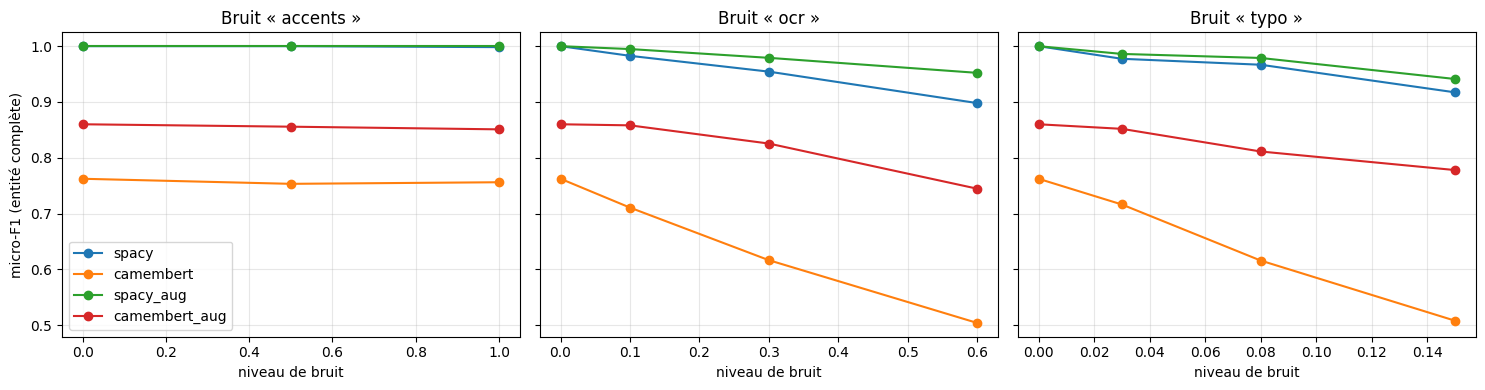

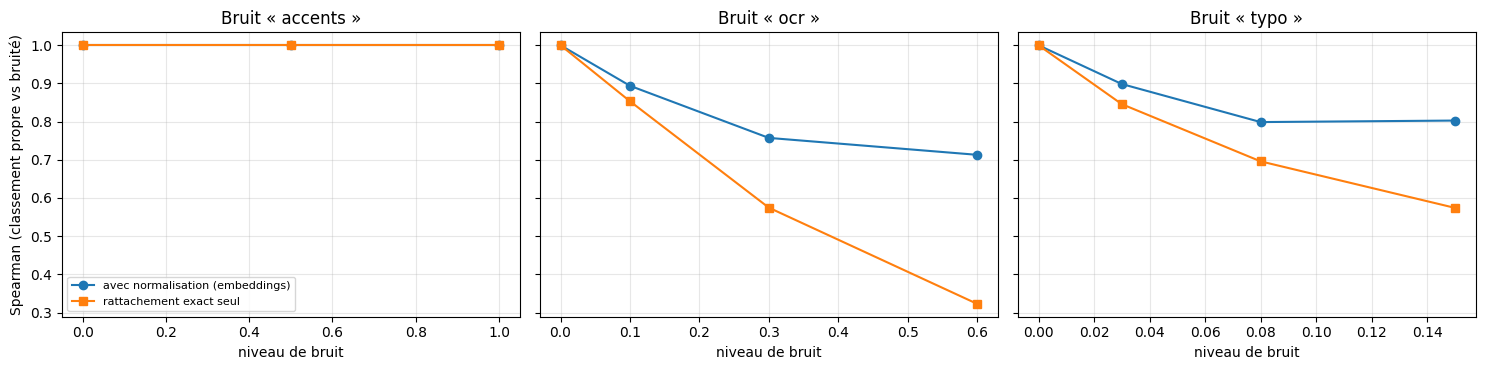

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, mode in zip(axes, NOISE_GRID):
    for model in NOISE_MODELS:
        d = noise_df[(noise_df["modèle"] == model) & (noise_df["bruit"] == mode)]
        ax.plot(d["niveau"], d["F1"], marker="o", label=model)
    ax.set_title(f"Bruit « {mode} »"); ax.set_xlabel("niveau de bruit"); ax.grid(alpha=.3)
axes[0].set_ylabel("micro-F1 (entité complète)"); axes[0].legend()
plt.tight_layout(); plt.savefig(FIGURES_DIR / "robustesse_f1.png", dpi=150); plt.show()

# Apport de la normalisation sur la stabilité du classement (extracteur retenu)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, mode in zip(axes, NOISE_GRID):
    d = noise_df[(noise_df["modèle"] == EXTRACTOR_NAME) & (noise_df["bruit"] == mode)]
    ax.plot(d["niveau"], d["stabilité (normalisation)"], marker="o", label="avec normalisation (embeddings)")
    ax.plot(d["niveau"], d["stabilité (rattachement exact)"], marker="s", label="rattachement exact seul")
    ax.set_title(f"Bruit « {mode} »"); ax.set_xlabel("niveau de bruit"); ax.grid(alpha=.3)
axes[0].set_ylabel("Spearman (classement propre vs bruité)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "robustesse_classement.png", dpi=150); plt.show()

## 15. Synthèse, limites et éthique

In [34]:
# Tableau de synthèse pour l'article (valeurs calculées, jamais saisies à la main)
syn = []
syn.append(("NER — micro-F1 test, spaCy (base de référence)", f"{comparison_ner.loc['spaCy (test)', 'micro-F1']:.3f}"))
syn.append(("NER — micro-F1 test, CamemBERT (modèle avancé)", f"{comparison_ner.loc['CamemBERT (test)', 'micro-F1']:.3f}"))
syn.append(("Normalisation — meilleure méthode (F1 test)", f"{BEST_ENC} : {norm_results.loc[BEST_ENC, 'F1 test']:.3f}"))
syn.append((f"Classement — Spearman (réf. : {REF_SOURCE})", f"{ranking_df.loc[f'pipeline ({EXTRACTOR_NAME})', 'Spearman']:.3f}"))
syn.append(("Classement — Spearman, score naïf", f"{ranking_df.loc['naïf (embeddings du texte brut)', 'Spearman']:.3f}"))
m0 = mitig[(mitig['anonymisation'] == 'aucune') & (mitig['scoreur'].str.startswith('B'))].iloc[0]
m3 = mitig[(mitig['anonymisation'] == 'complète') & (mitig['scoreur'].str.startswith('B'))].iloc[0]
syn.append(("Équité (score naïf) — écart max entre groupes, sans / avec anonymisation complète (z)",
            f"{m0['écart max entre groupes (z)']:.3f} → {m3['écart max entre groupes (z)']:.3f}"))
summary_df = pd.DataFrame(syn, columns=["résultat clé", "valeur"])
display(summary_df)
RESULTS["synthese"] = summary_df

# Export de tous les tableaux
for name, df in RESULTS.items():
    df.to_csv(REPORTS_DIR / f"{name}.csv", encoding="utf-8-sig")
print("Tableaux exportés dans", REPORTS_DIR, ":", sorted(RESULTS))

,résultat clé,valeur
0,"NER — micro-F1 test, spaCy (base de référence)",1.000
1,"NER — micro-F1 test, CamemBERT (modèle avancé)",0.871
2,Normalisation — meilleure méthode (F1 test),TF-IDF (base de référence) : 0.943
3,Classement — Spearman (réf. : classement manuel du groupe),0.960
4,"Classement — Spearman, score naïf",0.801
5,"Équité (score naïf) — écart max entre groupes, sans / avec anonymisation com...",0.693 → 0.000


Tableaux exportés dans c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\reports : ['classement', 'ner_comparison', 'ner_par_langue', 'normalisation', 'sensibilite_poids', 'synthese']


### Limites

- **Données synthétiques et très régulières** : les CV sont générés à partir de modèles de textes. Les scores NER élevés ne se transposent pas à des CV réels (mise en page libre, abréviations, fautes). Le volet robustesse n'en donne qu'une première approximation.
- **Annotations automatiques** : elles reposent sur un dictionnaire ; seul un échantillon de 30 CV est validé manuellement. Le modèle apprend en partie les règles de pré-annotation.
- **Petits effectifs** : 23 CV de test et 45 CV pour l'audit ; les intervalles de confiance sont larges et les tests statistiques peu puissants.
- **Classement de référence** : tant que le classement manuel n'est pas renseigné, les corrélations sont calculées contre une référence simulée et sont optimistes.
- **Score à poids fixes** : les pondérations sont des choix de conception, étudiés par sensibilité mais non appris. L'expérience est mesurée en mois de stage, ce qui avantage peu de candidats dans ce jeu.
- **Audit d'équité limité** : trois origines de noms, deux genres, un petit nombre de prénoms ; l'anonymisation par dictionnaire ne traite pas les proxys (établissement, ville, style).

### Aspects éthiques

- Aucune donnée personnelle réelle : noms, organisations et établissements sont fictifs ; si des CV réels sont ajoutés, les **anonymiser** avant tout traitement et citer la source de chaque jeu de données.
- Un système d'aide au recrutement relève d'un usage **à haut risque** (RGPD, AI Act) : le score doit rester une **aide à la décision**, avec explication des critères et possibilité de contestation, jamais une décision automatique.
- L'explicabilité (contributions par compétence) et l'audit d'équité ne garantissent pas l'absence de biais : ils doivent être répétés sur des données réelles avant tout usage.


In [35]:
# Traçabilité de l'exécution
import platform, sys
print("Python :", sys.version.split()[0], "|", platform.platform())
for lib in ("numpy", "pandas", "scipy", "sklearn", "spacy", "transformers", "torch", "sentence_transformers"):
    try:
        mod = __import__(lib)
        print(f"{lib:22s}", getattr(mod, "__version__", "?"))
    except ImportError:
        print(f"{lib:22s} non installé")
print("Graine :", SEED, "| extracteur retenu :", EXTRACTOR_NAME, "| référence du classement :", REF_SOURCE)

Python : 3.12.6 | Windows-11-10.0.26300-SP0
numpy                  2.3.1
pandas                 2.3.1
scipy                  1.16.3
sklearn                1.8.0
spacy                  3.8.18
transformers           5.5.4
torch                  2.11.0+cpu
sentence_transformers  5.4.1
Graine : 42 | extracteur retenu : spacy | référence du classement : classement manuel du groupe
